# Porto C 8×8 km — tốc độ lịch sử, giảm tốc và đánh giá ETA offline

Notebook tiếp nối `porto_region_coverage_expansion.ipynb`, dùng lại matching train đã hoàn tất.
Không sửa notebook/kết quả cũ, không tải OSM, không chạy lại matching train và không xây web.

**Pipeline:** kiểm chứng nguồn → loại chuyến vượt ranh giới split → lấy mẫu holdout độc lập
theo ngày–giờ → matching validation → profile giây/mét và B0/B1/M1/M2 → chọn cấu hình trên
validation → chốt cấu hình → matching/đánh giá test → khai phá train, coverage, độ nhạy và cụm chậm.

**Đối chiếu tài liệu:** giữ preprocessing → map matching → tốc độ → giảm tốc → cụm topology của
`Trajectory_Data_Mining_Porto.pdf`; dùng Overview của Zheng cho segmentation và map matching.
Điều chỉnh PDF: tách **train/validation/test**, giữ original_index, partial-edge distance, số quan sát
độc lập và fallback rõ ràng; dùng Leuven HMM đã kiểm chứng tại máy thay cho FMM chưa khả dụng.
Không dùng 168 ô/tuần mặc định; thử 1/2/4 giờ × weekday/weekend để giảm sparsity.
Web, A/B routing, API và phân tích lan truyền ùn tắc được hoãn đến giai đoạn demo.

Đây là học từ GPS taxi và thời gian nội suy, **không có nhãn ùn tắc độc lập**. Mẫu train được
chọn chủ đích để tăng độ phủ; không diễn giải các bảng như nhu cầu/ùn tắc của toàn bộ thành phố.

> **Bố cục repo:** notebook đã được chuyển vào thư mục theo bước và tự tìm thư mục gốc. Các output đang hiển thị được giữ từ lượt thực thi trước khi sắp xếp đường dẫn; không chạy lại matching/train trong bước sắp xếp này. Run All tiếp theo sẽ dùng đường dẫn mới và cache hợp lệ.

## A. Cấu hình và môi trường

`train_run` cố định lượt coverage đã hoàn tất; đổi sang nguồn khác phải kiểm tra provenance.
Mặc định giữ 34.501 chuyến đã chọn trước đây, loại toàn bộ chuyến vượt ranh giới train nếu có.
Lấy thêm 2.000 chuyến metadata cho mỗi holdout; không ưu tiên cạnh thiếu hoặc giờ cao điểm.
`smoke_test` giảm holdout còn 150 chuyến mỗi tập, chỉ kiểm tra kỹ thuật.

In [1]:
from pathlib import Path
import os, json
# Locate the repository from either its root or a notebook subfolder.
_current_dir = Path.cwd().resolve()
ROOT = next((candidate for candidate in (_current_dir, *_current_dir.parents)
             if (candidate / "notebooks").is_dir() and (candidate / "requirements").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the cloned repository (notebooks/ and requirements/ must exist).")
CFG = {
    "mode": "experiment",
    "train_run": "outputs/region_coverage_expansion/a3bc4981c0524eb0f19f",
    "data_path": "data/train.csv", "zip_member": None,
    "metadata_db": "cache/region_eda/metadata/e526ade57db9633e6c6b/trips.sqlite",
    "cache_dir": "cache/region_modeling", "output_dir": "outputs/region_modeling", "csv_dir": "outputs/csv",
    "seed": 313, "timezone": "Europe/Lisbon",
    "train_start": "2013-07-01T00:00:00+01:00",
    "train_end": "2013-08-05T00:00:00+01:00",
    "validation_end": "2013-08-19T00:00:00+01:00",
    "test_end": "2013-08-26T00:00:00+01:00",
    "holdout_trips": {"smoke_test": 150, "experiment": 2000},
    "chunk_size": 25000, "matching_workers": 6, "cpu_threads": 4,
    "matching_batch_size": 25, "force_rematch": False, "force_preprocess": False,
    "verify_full_hash": False,
    "analysis_unit": "edge", "min_unit_observed_distance_m": 15,
    "min_trips": 5, "min_taxis": 3, "min_days": 3,
    "history_candidates": [
        {"width": 1, "day_group": "weekday_weekend", "min_trips": 3},
        {"width": 2, "day_group": "weekday_weekend", "min_trips": 3},
        {"width": 4, "day_group": "weekday_weekend", "min_trips": 3},
        {"width": 1, "day_group": "weekday_weekend", "min_trips": 5},
        {"width": 2, "day_group": "weekday_weekend", "min_trips": 5},
        {"width": 4, "day_group": "weekday_weekend", "min_trips": 5},
    ],
    "reference_quantile": 0.85, "min_reference_speed_kmh": 3., "max_profile_speed_kmh": 120.,
    "slowdown_thresholds": [0.3, 0.4, 0.5, 0.6], "default_slowdown_threshold": 0.4,
    "support_candidates": [3, 5, 10], "min_recurrent_frequency": 0.5,
    "threshold_min_common_cells": 30, "threshold_slow_fraction_range": [0.01, 0.6],
    "min_cluster_edges": 2, "min_cluster_length_m": 100., "max_cluster_turn_degrees": 120.,
    "min_eta_duration_s": 30., "eta_sufficient_fraction": 0.8,
    "run_m2": True, "m2_max_train_rows": 100000,
    "m2_candidates": [
        {"max_iter": 80, "max_leaf_nodes": 15, "l2_regularization": 2.0},
        {"max_iter": 120, "max_leaf_nodes": 31, "l2_regularization": 5.0},
    ],
}
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[variable] = str(CFG["cpu_threads"])

In [2]:
# Nếu thiếu package, bỏ dấu # rồi chạy cell này trong đúng kernel và restart:
# %pip install -r "{ROOT / 'requirements/requirements_region_modeling.txt'}"

In [3]:
import ast, contextlib, hashlib, importlib.util, importlib.metadata, inspect, logging, math, sqlite3, sys, time, zipfile
from datetime import datetime, timezone
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import psutil, shapely, joblib
from shapely.geometry import Point, LineString, MultiLineString, box, mapping
from shapely.ops import substring
from pyproj import Transformer, Geod
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown
logging.getLogger("be.kuleuven.cs.dtai.mapmatching").setLevel(logging.ERROR)
REQUIRED = {"numpy":"numpy", "pandas":"pandas", "pyarrow":"pyarrow", "shapely":"shapely",
    "geopandas":"geopandas", "pyproj":"pyproj", "networkx":"networkx", "matplotlib":"matplotlib",
    "psutil":"psutil", "joblib":"joblib", "threadpoolctl":"threadpoolctl", "sklearn":"scikit-learn",
    "leuvenmapmatching":"leuvenmapmatching", "rtree":"rtree"}
missing = [name for module,name in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing: raise RuntimeError("Thiếu dependencies: " + ", ".join(missing))
VERSIONS = {name:importlib.metadata.version(name) for name in REQUIRED.values()}
def stable_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()

def file_hash(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda:handle.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def write_json(path,value):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(path.suffix+".tmp")
    payload=json.dumps(value,ensure_ascii=False,indent=2,default=str)
    # Windows readers or antivirus can briefly deny replacement of an open file.
    for attempt in range(10):
        try:
            temp.write_text(payload,encoding="utf-8")
            temp.replace(path)
            return
        except PermissionError:
            if attempt==9:
                raise
            time.sleep(min(.4,.025*(2**attempt)))

def csv_path(path):
    return ROOT/CFG["csv_dir"]/Path(path).resolve().relative_to((ROOT/"outputs").resolve()).with_suffix(".csv")

def write_table(frame,path,csv=False):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(".tmp.parquet")
    frame.to_parquet(temp,index=False); temp.replace(path)
    if csv:
        target=csv_path(path); target.parent.mkdir(parents=True,exist_ok=True)
        frame.to_csv(target,index=False,encoding="utf-8-sig")

def record_stage(name,status,detail):
    STAGES[name]={"status":status,"detail":str(detail)}
    write_json(RUN/"stage_status.json", STAGES)
    print(f"[{name}] {status}: {detail}")

@contextlib.contextmanager
def timed(name):
    before=time.perf_counter(); rss=psutil.Process().memory_info().rss/2**20
    try:
        yield
    finally:
        row={"stage":name,"seconds":time.perf_counter()-before,"rss_before_mb":rss,
             "rss_after_mb":psutil.Process().memory_info().rss/2**20}
        RUNTIME.append(row); write_json(RUN/"runtime.json",RUNTIME)
        print(f"{name}: {row['seconds']:.1f}s; RSS cuối bước={row['rss_after_mb']:.0f} MiB")

def save_figure(name):
    plt.tight_layout(); plt.savefig(FIGURES/(name+".png"),dpi=150,bbox_inches="tight")
    plt.show(); plt.close()

def utc(value): return pd.Timestamp(value).tz_convert("UTC")

def component_hash(names):
    selected={}
    notebook=json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    for cell in notebook["cells"]:
        if cell["cell_type"]!="code": continue
        source="".join(cell["source"]) if isinstance(cell["source"],list) else cell["source"]
        for node in ast.parse(source).body:
            if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and node.name in names:
                selected[node.name]=ast.dump(node,include_attributes=False)
    assert set(selected)==set(names)
    return stable_hash(selected)

TRAIN_SOURCE = ROOT/CFG["train_run"]
if not (TRAIN_SOURCE/"verification.json").exists():
    raise FileNotFoundError("Thiếu matching train đã hoàn tất; kiểm tra CFG['train_run'].")
SOURCE_CFG = json.loads((TRAIN_SOURCE/"config.json").read_text(encoding="utf-8"))
MATCH_KEYS = ["bbox", "metric_crs", "graph_buffer_m", "gps_interval_s", "min_points", "max_points_per_subtrajectory",
    "candidate_radius_m", "gps_error_m", "hmm_lattice_width", "microedge_max_m", "max_match_error_m",
    "max_mean_match_error_m", "min_matched_point_ratio", "min_retained_interval_ratio", "max_matched_speed_kmh",
    "max_detour_ratio", "detour_floor_m", "backward_jitter_m", "min_trip_points", "min_segment_points",
    "max_gps_speed_kmh", "broad_geo_bbox"]
CFG.update({key:SOURCE_CFG[key] for key in MATCH_KEYS})
BOUNDS = [utc(CFG[key]) for key in ["train_start", "train_end", "validation_end", "test_end"]]
assert all(a<b for a,b in zip(BOUNDS[:-1], BOUNDS[1:]))
assert CFG["mode"] in ["smoke_test", "experiment"]
assert len(CFG["history_candidates"]) <= 12 and len(CFG["m2_candidates"]) <= 3
assert all(24 % c["width"] == 0 for c in CFG["history_candidates"])
START, END = BOUNDS[0], BOUNDS[-1]
GEOD = Geod(ellps="WGS84")
PROJECT = Transformer.from_crs(4326,CFG["metric_crs"],always_xy=True)
STUDY_POLYGON = shapely.transform(box(*CFG["bbox"]),PROJECT.transform,interleaved=False)
BUFFER_POLYGON = STUDY_POLYGON.buffer(CFG["graph_buffer_m"])
BASE = ROOT/SOURCE_CFG["baseline_run"]
EDA_RUN = Path(json.loads((BASE/"data_source.json").read_text(encoding="utf-8"))["eda_run"])
if not EDA_RUN.exists(): EDA_RUN = ROOT/"outputs/region_eda"/EDA_RUN.name
DATA_PATH = ROOT/CFG["data_path"]
for path in [DATA_PATH, ROOT/CFG["metadata_db"], EDA_RUN/"sample_cleaning_audit.parquet"]:
    if not path.exists(): raise FileNotFoundError(f"Thiếu {path}; chưa có dữ liệu để chạy bước này.")
CACHE = ROOT/CFG["cache_dir"]; CACHE.mkdir(parents=True,exist_ok=True)
NOTEBOOK_PATH = ROOT/"notebooks/04_region_modeling/porto_region_modeling.ipynb"
CODE_HASH = stable_hash([c["source"] for c in json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))["cells"] if c["cell_type"]=="code"])
SOURCE_FILES = ["config.json", "combined_region_matching_parts.parquet", "combined_edge_traversals.parquet", "additional_selected_trips.parquet", "graph_reference.json"]
SOURCE_HASHES = {name:file_hash(TRAIN_SOURCE/name) for name in SOURCE_FILES}
SOURCE_HASHES["baseline_edges"] = file_hash(BASE/"edges.parquet")
SOURCE_HASHES["eda_cleaning_audit"] = file_hash(EDA_RUN/"sample_cleaning_audit.parquet")
SOURCE_HASHES["metadata_db"] = file_hash(ROOT/CFG["metadata_db"])
RUN_KEY = stable_hash([CFG,CODE_HASH,SOURCE_HASHES,VERSIONS])[:20]
MAIN_RUN = RUN = ROOT/CFG["output_dir"]/RUN_KEY
FIGURES = RUN/"figures"; FIGURES.mkdir(parents=True,exist_ok=True)
RUNTIME=[]; STAGES={}
write_json(RUN/"config.json",CFG)
write_json(RUN/"environment.json",{"python":sys.version,"packages":VERSIONS})
write_json(RUN/"provenance.json",{"train_source":str(TRAIN_SOURCE),"sha256":SOURCE_HASHES,"code_hash":CODE_HASH})
EDGES = gpd.read_parquet(BASE/"edges.parquet")
ranges=json.loads((BASE/"edge_inside_offset_ranges.json").read_text(encoding="utf-8"))
EDGES["inside_offset_ranges"] = EDGES.edge_id.map(ranges)
GRAPH_HASH = json.loads((TRAIN_SOURCE/"graph_reference.json").read_text(encoding="utf-8"))["graph_hash"]
assert EDGES.graph_hash.eq(GRAPH_HASH).all() and EDGES.crs.to_epsg()==32629
REGION_EDGES = EDGES[EDGES.length_inside_m>1e-8].copy()
UNIT_META = REGION_EDGES[["edge_id","length_m","road_class","x","y"]].rename(columns={"edge_id":"unit_id"})
write_json(RUN/"split_boundaries.json",dict(zip(["train_start","train_end","validation_end","test_end"],BOUNDS)))
display(pd.Series(VERSIONS,name="version").to_frame())
print("Output:",RUN)
print("Graph cố định:",len(REGION_EDGES),"cạnh có chiều dài dương trong vùng; không tải OSM.")

,version
numpy,2.1.3
pandas,2.3.2
pyarrow,23.0.1
shapely,2.2.0
geopandas,1.2.0
pyproj,3.8.0
networkx,3.5
matplotlib,3.10.0
psutil,7.1.0
joblib,1.5.2


Output: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\region_modeling\c01cada311f38e85a9d4
Graph cố định: 15882 cạnh có chiều dài dương trong vùng; không tải OSM.


## B. Giữ nguồn train và chuẩn bị holdout độc lập

Train kế thừa mẫu tăng coverage nên có thiên lệch chọn vùng/cạnh. Validation: **05/08–19/08/2013**,
test: **19/08–26/08/2013**, theo Lisbon, đều lấy từ `train.csv` chứa chuyến đầy đủ.
Không dùng bộ `test.csv` quỹ đạo dở dang của cuộc thi.

Phân tầng metadata theo ngày × giờ bắt đầu, quota tỷ lệ số chuyến sẵn có, chọn ngẫu nhiên có seed.
Giữ sampling_fraction của từng tầng. Việc chọn holdout không dùng cạnh đã phủ, tốc độ hay kết quả QA.
Đọc CSV theo chunk, chỉ parse GPS của TRIP_ID đã chọn; dừng khi đọc đủ những dòng được chọn.
Test được chuẩn bị vào cache cùng lượt đọc để tiết kiệm I/O; chỉ matching/đánh giá sau khi chốt mô hình.

Loại **toàn bộ chuyến** có GPS cuối chạm/vượt ranh giới split. GPS lỗi vẫn giữ original_index và
thời gian UTC gốc, tách khoảng trống/ra-vào vùng; giữ các điểm đứng yên.

In [4]:
def clean_gps(polyline,trip_timestamp,trip_id="trip",taxi_id="taxi",missing_flag=False):
    stats={"raw_points":0,"kept_points":0,"invalid_coordinates":0,"outside_broad_geography":0,
           "outside_study_time":0,"jump_links":0,"short_segment_points":0,"n_segments":0,
           "raw_duration_s":0.,"retained_duration_s":0.,"gps_distance_m":0.,"reason":"retained"}
    if str(missing_flag).strip().lower() in ["true","1"]:
        stats["reason"]="missing_data_true"; return [],stats
    try:
        coordinates=json.loads(polyline)
    except (ValueError,TypeError):
        stats["reason"]="invalid_json"; return [],stats
    if not isinstance(coordinates,list):
        stats["reason"]="invalid_polyline"; return [],stats
    stats["raw_points"]=len(coordinates)
    stats["raw_duration_s"]=max(0,len(coordinates)-1)*CFG["gps_interval_s"]
    if len(coordinates)<CFG["min_trip_points"]:
        stats["reason"]="empty_or_short_trip"; return [],stats
    west,south,east,north=CFG["broad_geo_bbox"]
    valid=[]
    for original_index,pair in enumerate(coordinates):
        timestamp=int(trip_timestamp)+CFG["gps_interval_s"]*original_index
        try:
            if not isinstance(pair,(list,tuple)) or len(pair)!=2: raise ValueError("coordinate shape")
            lon,lat=map(float,pair)
            if not np.isfinite([lon,lat]).all() or not (-180<=lon<=180 and -90<=lat<=90): raise ValueError("coordinate range")
        except (TypeError,ValueError,OverflowError):
            stats["invalid_coordinates"]+=1; continue
        if not (west<=lon<=east and south<=lat<=north):
            stats["outside_broad_geography"]+=1; continue
        if not (START.timestamp()<=timestamp<END.timestamp()):
            stats["outside_study_time"]+=1; continue
        valid.append({"trip_id":str(trip_id),"taxi_id":str(taxi_id),"original_index":original_index,
                      "timestamp":timestamp,"lon":lon,"lat":lat})
    segments=[]; segment=[]
    for point in valid:
        if segment:
            previous=segment[-1]
            distance=GEOD.inv(previous["lon"],previous["lat"],point["lon"],point["lat"])[2]
            dt=point["timestamp"]-previous["timestamp"]
            discontinuity=point["original_index"]!=previous["original_index"]+1
            jumping=distance/dt*3.6>CFG["max_gps_speed_kmh"]
            if discontinuity or jumping:
                stats["jump_links"]+=int(jumping and not discontinuity)
                if len(segment)>=CFG["min_segment_points"]: segments.append(segment)
                else: stats["short_segment_points"]+=len(segment)
                segment=[]
        segment.append(point)
    if segment:
        if len(segment)>=CFG["min_segment_points"]: segments.append(segment)
        else: stats["short_segment_points"]+=len(segment)
    if sum(map(len,segments))<CFG["min_trip_points"]:
        stats["reason"]="too_few_retained_points"; return [],stats
    kept=[]
    for number,part in enumerate(segments):
        for point in part:
            point["segment_id"]=f"{trip_id}:seg{number}"
            point["is_original_start"]=point["original_index"]==0
            point["is_original_end"]=point["original_index"]==len(coordinates)-1
            kept.append(point)
        for left,right in zip(part[:-1],part[1:]):
            assert right["original_index"]==left["original_index"]+1
            stats["gps_distance_m"]+=GEOD.inv(left["lon"],left["lat"],right["lon"],right["lat"])[2]
            stats["retained_duration_s"]+=right["timestamp"]-left["timestamp"]
    stats["kept_points"]=len(kept); stats["n_segments"]=len(segments)
    return kept,stats

@contextlib.contextmanager
def input_stream(path,member=None):
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as archive:
            names=[n for n in archive.namelist() if Path(n).name.lower()=="train.csv"]
            chosen=member or (names[0] if len(names)==1 else None)
            if chosen not in archive.namelist(): raise ValueError("ZIP phải chứa train.csv duy nhất, hoặc đặt zip_member.")
            with archive.open(chosen) as stream: yield stream
    else:
        with Path(path).open("rb") as stream: yield stream

def content_hash(path,member=None):
    h=hashlib.sha256()
    with input_stream(path,member) as stream:
        for block in iter(lambda:stream.read(1024*1024),b""): h.update(block)
    return h.hexdigest()

def split_context_points(points):
    points=points.sort_values(["trip_id","segment_id","original_index"]).copy()
    keep=shapely.covers(BUFFER_POLYGON,shapely.points(points.x.to_numpy(),points.y.to_numpy()))
    points=points.loc[keep].copy()
    previous=points.shift()
    new=points.trip_id.ne(previous.trip_id)|points.segment_id.ne(previous.segment_id)|points.original_index.ne(previous.original_index+1)
    points["context_run"]=new.cumsum()
    subs=[]; skipped=0
    for _,frame in points.groupby("context_run",sort=False):
        if len(frame)<CFG["min_points"]:
            skipped+=1
            continue
        records=frame[["original_index","timestamp","x","y"]].to_dict("records")
        width=CFG["max_points_per_subtrajectory"]
        for start in range(0,len(records)-1,width-1):
            block=records[start:start+width]
            if len(block)<CFG["min_points"]:
                skipped+=1
                continue
            first=frame.iloc[0]
            sid=f"{first.trip_id}:{first.segment_id}:context{int(first.context_run)}:p{block[0]['original_index']}"
            subs.append({"trip_id":str(first.trip_id),"taxi_id":str(first.taxi_id),"subtrajectory_id":sid,
                         "split":"train_pilot","points":block})
    return subs,skipped

def verified_data_hash():
    previous=json.loads((TRAIN_SOURCE/"source_input_fingerprint.json").read_text(encoding="utf-8"))
    stat=DATA_PATH.stat()
    fingerprint={"path":str(DATA_PATH.resolve()),"size":stat.st_size,"mtime_ns":stat.st_mtime_ns,"zip_member":CFG["zip_member"]}
    reuse=not CFG["verify_full_hash"] and fingerprint==previous["fingerprint"]
    digest=previous["content_sha256"] if reuse else content_hash(DATA_PATH,CFG["zip_member"])
    if digest!=previous["content_sha256"]: raise RuntimeError("Dữ liệu khác nguồn train đã xác minh; dừng để tránh trộn cache.")
    write_json(MAIN_RUN/"source_input_fingerprint.json",{"fingerprint":fingerprint,"content_sha256":digest,"reused_verified_hash":reuse})
    return digest

def select_holdout_metadata():
    connection=sqlite3.connect(f"file:{(ROOT/CFG['metadata_db']).as_posix()}?mode=ro",uri=True)
    frames=[]; quotas=[]
    try:
        for split,start,end in [("validation",BOUNDS[1],BOUNDS[2]),("test",BOUNDS[2],BOUNDS[3])]:
            source=pd.read_sql_query("SELECT * FROM trips WHERE status='metadata_valid' AND timestamp>=? AND timestamp<? ORDER BY source_row",connection,
                                     params=[int(start.timestamp()),int(end.timestamp())])
            if source.empty: raise RuntimeError(f"Không có metadata {split}; kiểm tra khoảng ngày và DB.")
            counts=source.groupby(["day","hour"],sort=True).size().rename("available").reset_index()
            budget=min(CFG["holdout_trips"][CFG["mode"]],len(source))
            ideal=budget*counts.available/len(source); counts["quota"]=np.floor(ideal).astype(int)
            remaining=budget-int(counts.quota.sum())
            order=(ideal-counts.quota).sort_values(ascending=False,kind="stable").index[:remaining]
            counts.loc[order,"quota"]+=1
            chosen=[]
            for row in counts.itertuples():
                group=source[(source.day==row.day)&(source.hour==row.hour)]
                if row.quota:
                    seed=int(stable_hash([CFG["seed"],split,row.day,int(row.hour)])[:16],16)
                    positions=np.random.default_rng(seed).choice(len(group),row.quota,replace=False)
                    chosen.append(group.iloc[positions])
            sample=pd.concat(chosen,ignore_index=True)
            sample["split"]=split
            counts["split"]=split;counts["sampling_fraction"]=counts.quota/counts.available
            sample=sample.merge(counts[["day","hour","sampling_fraction"]],on=["day","hour"],validate="many_to_one")
            assert len(sample)==budget and sample.trip_id.is_unique
            frames.append(sample);quotas.append(counts)
    finally: connection.close()
    return pd.concat(frames,ignore_index=True),pd.concat(quotas,ignore_index=True)

def prepare_holdouts(folder,selected):
    global START,END
    marker=folder/"complete.json"
    if marker.exists() and not CFG["force_preprocess"]:
        print("Dùng cache holdout inputs:",folder.name)
        return pd.read_parquet(folder/"trip_audit.parquet")
    folder.mkdir(parents=True,exist_ok=True)
    lookup=selected.set_index("trip_id").to_dict("index");found=set();audit=[];nread=0
    handles={s:(folder/f"{s}_subtrajectories.jsonl").open("w",encoding="utf-8") for s in ["validation","test"]}
    try:
        with input_stream(DATA_PATH,CFG["zip_member"]) as stream:
            for chunk in pd.read_csv(stream,usecols=["TRIP_ID","TAXI_ID","TIMESTAMP","MISSING_DATA","POLYLINE"],
                    dtype={"TRIP_ID":"string","TAXI_ID":"string"},chunksize=CFG["chunk_size"]):
                chunk["source_row"]=np.arange(nread,nread+len(chunk));nread+=len(chunk)
                chosen=chunk[chunk.TRIP_ID.isin(lookup)]
                for raw in chosen.itertuples(index=False):
                    meta=lookup[str(raw.TRIP_ID)]
                    if int(raw.source_row)!=int(meta["source_row"]) or str(raw.TRIP_ID) in found: continue
                    trip_id=str(raw.TRIP_ID);found.add(trip_id)
                    split=meta["split"];START,END=(BOUNDS[1],BOUNDS[2]) if split=="validation" else (BOUNDS[2],BOUNDS[3])
                    points,stats=clean_gps(raw.POLYLINE,int(raw.TIMESTAMP),trip_id,str(raw.TAXI_ID),raw.MISSING_DATA)
                    raw_end=int(raw.TIMESTAMP)+stats["raw_duration_s"]
                    crossing=raw_end>=END.timestamp()
                    record={"trip_id":trip_id,"taxi_id":str(raw.TAXI_ID),"split":split,"timestamp":int(raw.TIMESTAMP),
                        "trip_end_timestamp":raw_end,"sampling_fraction":meta["sampling_fraction"],**stats,
                        "boundary_excluded":bool(crossing),"in_region":False,"n_subtrajectories":0}
                    if crossing:
                        record["reason"]="crosses_split_boundary"
                    elif points:
                        frame=pd.DataFrame(points)
                        w,s,e,n=CFG["bbox"]
                        inside=frame.lon.between(w,e)&frame.lat.between(s,n)
                        record["in_region"]=bool(inside.any())
                        if inside.any():
                            frame["x"],frame["y"]=PROJECT.transform(frame.lon.to_numpy(),frame.lat.to_numpy())
                            subs,skipped=split_context_points(frame)
                            record["n_subtrajectories"]=len(subs);record["short_context_excluded"]=skipped
                            for sub in subs:
                                sub["split"]=split
                                assert all(p["timestamp"]==int(raw.TIMESTAMP)+15*p["original_index"] for p in sub["points"])
                                handles[split].write(json.dumps(sub,ensure_ascii=False)+"\n")
                            if not subs: record["reason"]="no_matchable_context"
                        else: record["reason"]="no_clean_gps_in_region"
                    audit.append(record)
                if len(found)==len(lookup): break
        if found!=set(lookup): raise RuntimeError(f"Thiếu {len(set(lookup)-found)} dòng CSV đã chọn; kiểm tra nguồn/metadata.")
    finally:
        for handle in handles.values(): handle.close()
        START,END=BOUNDS[0],BOUNDS[-1]
    result=pd.DataFrame(audit)
    write_table(result,folder/"trip_audit.parquet")
    write_json(marker,{"selected_trips":len(selected),"source_rows_read":nread,"audit_rows":len(result)})
    return result

with timed("verify_train_and_prepare_holdouts"):
    DATA_HASH=verified_data_hash()
    BASE_SELECTED=pd.read_parquet(BASE/"selected_trips.parquet")
    EXTRA_SELECTED=pd.read_parquet(TRAIN_SOURCE/"additional_selected_trips.parquet")
    ALL_TRAIN_SELECTED=pd.concat([BASE_SELECTED[["trip_id","taxi_id","timestamp"]],EXTRA_SELECTED[["trip_id","taxi_id","timestamp"]]],ignore_index=True)
    assert ALL_TRAIN_SELECTED.trip_id.is_unique
    cleaning_audit=pd.read_parquet(EDA_RUN/"sample_cleaning_audit.parquet")
    BOUNDARY_IDS=set(cleaning_audit.loc[cleaning_audit.timestamp+cleaning_audit.raw_duration_s>=BOUNDS[1].timestamp(),"trip_id"]) & set(ALL_TRAIN_SELECTED.trip_id)
    TRAIN_SELECTED=ALL_TRAIN_SELECTED[~ALL_TRAIN_SELECTED.trip_id.isin(BOUNDARY_IDS)].copy()
    write_table(ALL_TRAIN_SELECTED[ALL_TRAIN_SELECTED.trip_id.isin(BOUNDARY_IDS)],RUN/"train_boundary_excluded.parquet",csv=True)
    TRAIN_IDS=set(TRAIN_SELECTED.trip_id)
    TRAIN_TRAVERSALS=pd.read_parquet(TRAIN_SOURCE/"combined_edge_traversals.parquet")
    TRAIN_TRAVERSALS=TRAIN_TRAVERSALS[TRAIN_TRAVERSALS.trip_id.isin(TRAIN_IDS)].assign(split="train")
    TRAIN_TRAVERSALS["unit_id"]=TRAIN_TRAVERSALS.edge_id
    assert TRAIN_TRAVERSALS.exit_time.lt(BOUNDS[1]).all()
    HOLDOUT_SELECTED,SAMPLING_QUOTAS=select_holdout_metadata()
    assert not set(HOLDOUT_SELECTED.trip_id)&set(ALL_TRAIN_SELECTED.trip_id)
    PREP_KEY=stable_hash([DATA_HASH,SOURCE_HASHES["metadata_db"],GRAPH_HASH,
        {k:CFG[k] for k in MATCH_KEYS},CFG["seed"],CFG["holdout_trips"][CFG["mode"]],list(map(str,BOUNDS)),
        HOLDOUT_SELECTED[["trip_id","split","source_row"]].to_dict("records"),
        component_hash(["clean_gps","split_context_points","prepare_holdouts","select_holdout_metadata"])])[:24]
    HOLDOUT_FOLDER=CACHE/"holdouts"/PREP_KEY
    TRIP_AUDIT=prepare_holdouts(HOLDOUT_FOLDER,HOLDOUT_SELECTED)
    write_table(HOLDOUT_SELECTED,RUN/"holdout_selected_trips.parquet")
    write_table(SAMPLING_QUOTAS,RUN/"holdout_sampling_by_day_hour.parquet",csv=True)
    write_table(TRIP_AUDIT,RUN/"holdout_cleaning_audit.parquet")
    write_json(RUN/"holdout_cache.json",{"folder":str(HOLDOUT_FOLDER),"key":PREP_KEY})
    write_json(RUN/"train_boundary_policy.json",{"policy":"exclude_complete_trip_if_raw_last_gps_touches_or_crosses_split_end",
        "excluded_trip_ids":sorted(BOUNDARY_IDS),"selected_before":len(ALL_TRAIN_SELECTED),"selected_after":len(TRAIN_SELECTED),
        "original_matching_outputs_unchanged":True})
    display(HOLDOUT_SELECTED.groupby("split").agg(trips=("trip_id","nunique"),days=("day","nunique"),taxis=("taxi_id","nunique")))
    print("Train:",len(TRAIN_SELECTED),"chuyến sau loại",len(BOUNDARY_IDS),"chuyến vượt ranh giới; giữ matching đã có.")
    print("CSV rows read for holdout:",json.loads((HOLDOUT_FOLDER/"complete.json").read_text())["source_rows_read"])
    record_stage("inputs","complete","Nguồn train giữ nguyên; holdout có seed, độc lập và tách theo chuyến.")

,trips,days,taxis
split,,,
test,2000,7,383
validation,2000,14,408


Train: 34500 chuyến sau loại 1 chuyến vượt ranh giới; giữ matching đã có.
CSV rows read for holdout: 275000
[inputs] complete: Nguồn train giữ nguyên; holdout có seed, độc lập và tách theo chuyến.
verify_train_and_prepare_holdouts: 17.7s; RSS cuối bước=846 MiB


## C. Matching holdout và QA

Giữ nguyên Leuven HMM, road graph, partial-edge/time allocation và toàn bộ ngưỡng QA của train.
Matcher trả kết quả và kết quả đạt QA là hai trạng thái khác nhau. Mỗi batch có cache gắn nguồn GPS,
graph, code matching, cấu hình và phiên bản. Timestamp dùng original_index, không nối qua khoảng trống.
Thời gian 15 giây được phân bổ tỷ lệ khoảng cách, không dùng tốc độ train để tạo nhãn test.

In [5]:
def collapse_parts(parts):
    combined = []
    for edge_id, start_offset, end_offset in parts:
        if end_offset < start_offset-CFG["backward_jitter_m"]:
            raise ValueError("backward_offset")
        end_offset = max(start_offset,end_offset)
        if combined and combined[-1][0] == edge_id and abs(combined[-1][2]-start_offset)<.01:
            combined[-1] = (edge_id,combined[-1][1],end_offset)
        else:
            combined.append((edge_id,float(start_offset),float(end_offset)))
    return combined

class LeuvenAdapter:
    name = "leuven_hmm"
    def __init__(self, edges, cache_dir):
        from leuvenmapmatching.map.inmem import InMemMap
        from leuvenmapmatching.matcher.distance import DistanceMatcher
        self.matcher_class = DistanceMatcher
        graph, self.micro = {}, {}
        node_map = {int(value):index for index,value in enumerate(sorted(set(edges.u)|set(edges.v)))}
        next_node = len(node_map)
        for row in edges.itertuples():
            coordinates = list(row.geometry.coords)
            # Ít nhất 2 microedges: phân biệt song song kể cả cạnh thẳng.
            if len(coordinates)==2:
                middle = row.geometry.interpolate(.5,normalized=True)
                coordinates.insert(1,(middle.x,middle.y))
            dense = [coordinates[0]]
            for a,b in zip(coordinates[:-1],coordinates[1:]):
                distance = np.hypot(b[0]-a[0],b[1]-a[1])
                for fraction in np.linspace(0,1,max(1,int(np.ceil(distance/CFG["microedge_max_m"])))+1)[1:]:
                    dense.append((a[0]+fraction*(b[0]-a[0]),a[1]+fraction*(b[1]-a[1])))
            labels = [node_map[int(row.u)]]
            for _ in dense[1:-1]:
                labels.append(next_node)
                next_node += 1
            labels.append(node_map[int(row.v)])
            offset = 0.0
            for index,(a,b) in enumerate(zip(dense[:-1],dense[1:])):
                length = float(np.hypot(b[0]-a[0],b[1]-a[1]))
                if length<1e-8:
                    raise ValueError("Zero length vertex segment trong road geometry.")
                left,right = labels[index],labels[index+1]
                for node,coordinate in [(left,a),(right,b)]:
                    if node not in graph:
                        graph[node] = ((coordinate[1],coordinate[0]),[])
                graph[left][1].append(right)
                self.micro[(left,right)] = {"edge_id":row.edge_id,"start":offset,"length":length,
                                           "line":LineString([a,b])}
                offset += length
        self.map = InMemMap("porto_projected_directed",graph=graph,use_latlon=False,use_rtree=True,index_edges=True)

    def match(self, points):
        matcher = self.matcher_class(self.map,max_dist=CFG["candidate_radius_m"],
                    max_dist_init=CFG["candidate_radius_m"],obs_noise=CFG["gps_error_m"],
                    dist_noise=CFG["gps_error_m"]*2,min_prob_norm=.001,
                    max_lattice_width=CFG["hmm_lattice_width"],non_emitting_states=True,
                    only_edges=True,avoid_goingback=True)
        matcher.match([(p["y"],p["x"]) for p in points],unique=False)
        lattice = matcher.lattice_best or []
        if lattice and not all(hasattr(lattice[0],name) for name in ["obs","obs_ne","edge_m","dist_obs"]):
            raise RuntimeError("Leuven lattice API không tương thích với adapter.")
        emitting = [(position,state) for position,state in enumerate(lattice) if state.obs_ne==0]
        intervals, matched_points = [], []
        for position,state in emitting:
            index = int(state.obs)
            micro = self.micro[(state.edge_m.l1,state.edge_m.l2)]
            raw = Point(points[index]["x"],points[index]["y"])
            snapped = micro["line"].interpolate(micro["line"].project(raw))
            matched_points.append({"point_index":index,"edge_id":micro["edge_id"],
                                   "matched_x":snapped.x,"matched_y":snapped.y,"error_m":snapped.distance(raw)})
        for (left_position,left),(right_position,right) in zip(emitting[:-1],emitting[1:]):
            i,j = int(left.obs),int(right.obs)
            if j!=i+1:
                continue
            sequence = []
            for state in lattice[left_position:right_position+1]:
                key = (state.edge_m.l1,state.edge_m.l2)
                if not sequence or sequence[-1]!=key:
                    sequence.append(key)
            if any(a[1]!=b[0] for a,b in zip(sequence[:-1],sequence[1:])):
                continue
            parts = []
            for position,key in enumerate(sequence):
                micro = self.micro[key]
                begin,end = 0.0,micro["length"]
                if position==0:
                    begin = micro["line"].project(Point(points[i]["x"],points[i]["y"]))
                if position==len(sequence)-1:
                    end = micro["line"].project(Point(points[j]["x"],points[j]["y"]))
                parts.append((micro["edge_id"],micro["start"]+begin,micro["start"]+end))
            try:
                parts = collapse_parts(parts)
            except ValueError:
                continue
            intervals.append({"i":i,"j":j,"parts":parts,"error_m":max(float(left.dist_obs),float(right.dist_obs))})
        return intervals,matched_points

def interval_pieces(parts, duration_s):
    """Nội suy chỉ theo độ dài; tổng thời gian đúng bằng khoảng GPS."""
    distances = np.array([max(0.0,b-a) for _,a,b in parts])
    if distances.sum()==0:
        if len(parts)!=1:
            raise ValueError("zero_distance_multiple_edges")
        durations = np.array([duration_s],dtype=float)
    else:
        durations = duration_s*distances/distances.sum()
        durations[-1] += duration_s-durations.sum()
    return [(edge,a,b,float(d),float(t)) for (edge,a,b),d,t in zip(parts,distances,durations) if t>1e-10]

def match_subtrajectory(sub, engine, edge_lookup):
    points = sub["points"]
    intervals, snapped = engine.match(points)
    snapped_unique = {int(item["point_index"]):item for item in snapped}
    returned = bool(intervals)
    point_ratio = len(snapped_unique)/len(points)
    mean_error = float(np.mean([p["error_m"] for p in snapped])) if snapped else np.nan
    audits, accepted = [], []
    seen = set()
    for interval in intervals:
        i,j,parts = interval["i"],interval["j"],interval["parts"]
        if (i,j) in seen:
            continue
        seen.add((i,j))
        reason = "accepted"
        dt = points[j]["timestamp"]-points[i]["timestamp"]
        distance = sum(max(0,b-a) for _,a,b in parts)
        straight = float(np.hypot(points[j]["x"]-points[i]["x"],points[j]["y"]-points[i]["y"]))
        if j!=i+1 or points[j]["original_index"]!=points[i]["original_index"]+1 or dt!=CFG["gps_interval_s"]:
            reason = "nonconsecutive_gps"
        elif not parts:
            reason = "empty_path"
        elif distance <= 1e-8 and len(parts) > 1:
            reason = "ambiguous_stationary_edge_assignment"
        elif interval["error_m"]>CFG["max_match_error_m"]:
            reason = "gps_road_error"
        elif any(edge not in edge_lookup for edge,_,_ in parts):
            reason = "unknown_edge"
        elif any(a<-.05 or b>edge_lookup[e].length_m+.05 or b<a for e,a,b in parts):
            reason = "invalid_offset"
        elif any(edge_lookup[a[0]].v!=edge_lookup[b[0]].u for a,b in zip(parts[:-1],parts[1:])):
            reason = "disconnected_path"
        elif distance/dt*3.6>CFG["max_matched_speed_kmh"]:
            reason = "implausible_matched_speed"
        elif distance>CFG["max_detour_ratio"]*max(CFG["detour_floor_m"],straight):
            reason = "excessive_detour"
        audits.append({"subtrajectory_id":sub["subtrajectory_id"],"trip_id":sub["trip_id"],
                       "original_start_index":points[i]["original_index"],"original_end_index":points[j]["original_index"],
                       "gps_duration_s":dt,"matched_distance_m":distance,"raw_chord_m":straight,"status":reason})
        if reason=="accepted":
            accepted.append(interval)
    for i in range(len(points)-1):
        if (i,i+1) not in seen:
            audits.append({"subtrajectory_id":sub["subtrajectory_id"],"trip_id":sub["trip_id"],
                "original_start_index":points[i]["original_index"],"original_end_index":points[i+1]["original_index"],
                "gps_duration_s":points[i+1]["timestamp"]-points[i]["timestamp"],"matched_distance_m":np.nan,
                "raw_chord_m":float(np.hypot(points[i+1]["x"]-points[i]["x"],points[i+1]["y"]-points[i]["y"])),
                "status":"matcher_omitted_interval"})
    accepted.sort(key=lambda item:item["i"])
    retained_ratio = len(accepted)/max(1,len(points)-1)
    quality_ok = (returned and point_ratio>=CFG["min_matched_point_ratio"]
                  and retained_ratio>=CFG["min_retained_interval_ratio"]
                  and mean_error<=CFG["max_mean_match_error_m"])
    rows, run_index, last_j = [], -1, None
    for interval in accepted if quality_ok else []:
        i,j = interval["i"],interval["j"]
        if i!=last_j:
            run_index += 1
        last_j = j
        interval_id = f"{sub['subtrajectory_id']}:{points[i]['original_index']}:{points[j]['original_index']}"
        start = pd.Timestamp(points[i]["timestamp"],unit="s",tz="UTC")
        finish = pd.Timestamp(points[j]["timestamp"],unit="s",tz="UTC")
        allocated = interval_pieces(interval["parts"],(finish-start).total_seconds())
        cursor = start
        for part_index,(edge_id,begin,end,distance,duration) in enumerate(allocated):
            exit_time = finish if part_index==len(allocated)-1 else cursor+pd.Timedelta(seconds=duration)
            exact_duration = (exit_time.value-cursor.value)/1e9
            rows.append({"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],
                         "route_id":f"{sub['subtrajectory_id']}:run{run_index}","split":sub["split"],
                         "interval_id":interval_id,"part_index":part_index,"edge_id":edge_id,
                         "entry_offset_m":begin,"exit_offset_m":end,"entry_time":cursor,"exit_time":exit_time,
                         "distance_traversed_m":distance,"duration_s":exact_duration,
                         "speed_kmh":3.6*distance/exact_duration,"match_quality":max(0.0,1-interval["error_m"]/CFG["candidate_radius_m"]),
                         "gps_road_error_m":interval["error_m"],"is_interpolated":len(allocated)>1,
                         "interval_fanout":len(allocated),"original_start_index":points[i]["original_index"],
                         "original_end_index":points[j]["original_index"],"gps_start_time":start,"gps_end_time":finish,
                         "backend":engine.name,"match_status":"analysis_accepted"})
            cursor = exit_time
        assert abs(sum(r["duration_s"] for r in rows[-len(allocated):])-(finish-start).total_seconds())<1e-5
    qa = {"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],"split":sub["split"],
          "n_points":len(points),"n_intervals":len(points)-1,"n_matched_points":len(snapped_unique),
          "n_retained_points":len({i for item in accepted for i in [item["i"],item["j"]]}) if quality_ok else 0,
          "n_accepted_intervals":len(accepted) if quality_ok else 0,"candidate_accepted_intervals":len(accepted),
          "matcher_returned":returned,"analysis_accepted":quality_ok,"mean_error_m":mean_error,
          "matched_point_ratio":point_ratio,"retained_interval_ratio":retained_ratio,
          "raw_distance_m":sum(np.hypot(b["x"]-a["x"],b["y"]-a["y"]) for a,b in zip(points[:-1],points[1:])),
          "retained_raw_chord_m":sum(a["raw_chord_m"] for a in audits if a["status"]=="accepted") if quality_ok else 0,
          "backend":engine.name,"error":""}
    for point in snapped_unique.values():
        original = points[point["point_index"]]
        point.update({"trip_id":sub["trip_id"],"subtrajectory_id":sub["subtrajectory_id"],
                      "original_index":original["original_index"],"timestamp":original["timestamp"],
                      "raw_x":original["x"],"raw_y":original["y"],"analysis_accepted":quality_ok})
    return rows,qa,list(snapped_unique.values()),audits

def run_matching(parts_path,engine,edges,matching_key):
    """Independent CPU workers; cache every completed batch and preserve order."""
    folder=CACHE/"matching"/matching_key
    folder.mkdir(parents=True,exist_ok=True)
    backend_name=engine.name
    batches=[]; batch=[]
    with parts_path.open(encoding="utf-8") as handle:
        for line in handle:
            batch.append(json.loads(line))
            if len(batch)>=CFG["matching_batch_size"]:
                batches.append(batch); batch=[]
    if batch:
        batches.append(batch)

    def flush(items,index):
        import sys,types
        prefix=folder/f"batch_{index:05d}"
        paths={name:prefix.with_name(prefix.name+f"_{name}.parquet") for name in ["parts","qa","points","interval_qa"]}
        marker=prefix.with_suffix(".json")
        identity=stable_hash([matching_key,items])
        if marker.exists() and all(p.exists() for p in paths.values()) and not CFG["force_rematch"]:
            if json.loads(marker.read_text(encoding="utf-8"))["identity"]==identity:
                return index,paths,True,psutil.Process().memory_info().rss/2**20
        # Per-process module state keeps Rtree/HMM maps off the pickle boundary.
        module=sys.modules.setdefault("_porto_leuven_process_cache",types.ModuleType("_porto_leuven_process_cache"))
        if getattr(module,"key",None)!=matching_key:
            module.engine=LeuvenAdapter(edges,folder)
            module.lookup={row.edge_id:row for row in edges.itertuples()}
            module.key=matching_key
        groups={name:[] for name in paths}
        for sub in items:
            try:
                rows,qa,snapped,audits=match_subtrajectory(sub,module.engine,module.lookup)
                groups["parts"].extend(rows); groups["qa"].append(qa)
                groups["points"].extend(snapped); groups["interval_qa"].extend(audits)
            except Exception as error:
                groups["qa"].append({"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],
                    "split":sub["split"],"n_points":len(sub["points"]),"n_intervals":len(sub["points"])-1,
                    "n_matched_points":0,"n_retained_points":0,"n_accepted_intervals":0,
                    "matcher_returned":False,"analysis_accepted":False,"mean_error_m":np.nan,
                    "raw_distance_m":sum(np.hypot(b["x"]-a["x"],b["y"]-a["y"]) for a,b in zip(sub["points"][:-1],sub["points"][1:])),
                    "retained_raw_chord_m":0.,"backend":backend_name,"error":f"{type(error).__name__}: {error}"})
        for name,path in paths.items():
            write_table(pd.DataFrame(groups[name]),path)
        write_json(marker,{"identity":identity,"matching_key":matching_key,"subtrajectories":len(items)})
        return index,paths,False,psutil.Process().memory_info().rss/2**20

    workers=max(1,min(int(CFG.get("matching_workers",1)),len(batches)))
    started=time.perf_counter(); saved={}; completed=0; hits=0; worker_rss=0.
    total_subs=sum(map(len,batches))
    progress_path=RUN/"matching_progress.json"
    write_json(progress_path,{"status":"running","completed_batches":0,"total_batches":len(batches),
        "completed_subtrajectories":0,"total_subtrajectories":total_subs,"workers":workers})
    with parallel_config(backend="loky",inner_max_num_threads=1):
        results=Parallel(n_jobs=workers,return_as="generator_unordered",pre_dispatch=workers*2,max_nbytes=None)(
            delayed(flush)(items,index) for index,items in enumerate(batches))
        for index,paths,cache_hit,rss in results:
            saved[index]=paths; completed+=len(batches[index]); hits+=int(cache_hit); worker_rss=max(worker_rss,rss)
            elapsed=time.perf_counter()-started
            write_json(progress_path,{"status":"running","completed_batches":len(saved),"total_batches":len(batches),
                "completed_subtrajectories":completed,"total_subtrajectories":total_subs,"workers":workers,
                "cache_hits":hits,"elapsed_s":elapsed,"max_single_worker_rss_mb":worker_rss})
            if len(saved)%5==0 or len(saved)==len(batches):
                print(f"Matching: {completed}/{total_subs} subtrajectories; batches {len(saved)}/{len(batches)}; "
                      f"elapsed={elapsed:.1f}s; workers={workers}",flush=True)
    outputs={}
    for name in ["parts","qa","points","interval_qa"]:
        frames=[pd.read_parquet(saved[i][name]) for i in sorted(saved)]
        outputs[name]=pd.concat([f for f in frames if not f.empty],ignore_index=True) if any(not f.empty for f in frames) else pd.DataFrame()
    write_json(RUN/"matching_cache.json",{"matching_key":matching_key,"folder":str(folder),"backend":backend_name,
        "workers":workers,"cached_batches":hits,"batch_count":len(batches),"max_single_worker_rss_mb":worker_rss})
    write_json(progress_path,{"status":"complete","completed_batches":len(saved),"total_batches":len(batches),
        "completed_subtrajectories":completed,"total_subtrajectories":total_subs,"workers":workers,
        "cache_hits":hits,"elapsed_s":time.perf_counter()-started,"max_single_worker_rss_mb":worker_rss})
    return outputs

def clip_parts_to_region(parts,edges):
    lookup={r.edge_id:r for r in edges.itertuples()}; rows=[]
    for original in parts.to_dict("records"):
        edge=lookup[original["edge_id"]]; a=original["entry_offset_m"]; b=original["exit_offset_m"]
        if b-a<=1e-8:
            intersections=[(a,b)] if STUDY_POLYGON.covers(edge.geometry.interpolate(a)) else []
        else:
            intersections=[(max(a,left),min(b,right)) for left,right in edge.inside_offset_ranges if min(b,right)>max(a,left)+1e-8]
        for j,(left,right) in enumerate(intersections):
            row=original.copy(); duration=original["duration_s"]
            f0=(left-a)/(b-a) if b>a else 0.; f1=(right-a)/(b-a) if b>a else 1.
            start=pd.Timestamp(original["entry_time"]); finish=pd.Timestamp(original["exit_time"])
            row.update(entry_offset_m=left,exit_offset_m=right,distance_traversed_m=right-left,
                entry_time=start+pd.Timedelta(seconds=duration*f0),exit_time=finish if f1==1 else start+pd.Timedelta(seconds=duration*f1),
                boundary_interpolated=f0>1e-8 or f1<1-1e-8,is_interpolated=bool(original["is_interpolated"] or f0>1e-8 or f1<1-1e-8),
                region_piece_index=j,buffer_route_id=original["route_id"],graph_hash=GRAPH_HASH,
                time_allocation="distance_proportional_within_original_gps_interval")
            row["duration_s"]=(row["exit_time"].value-row["entry_time"].value)/1e9
            if row["duration_s"]<=0:
                continue
            row["speed_kmh"]=3.6*row["distance_traversed_m"]/row["duration_s"]
            rows.append(row)
    if not rows:
        return pd.DataFrame()
    frame=pd.DataFrame(rows).sort_values(["subtrajectory_id","entry_time","part_index","region_piece_index"]).reset_index(drop=True)
    previous=frame.shift()
    continuous=(frame.subtrajectory_id.eq(previous.subtrajectory_id)&frame.buffer_route_id.eq(previous.buffer_route_id)
                &((frame.entry_time-previous.exit_time).dt.total_seconds().abs()<1e-5))
    frame["visit_number"]=(~continuous).cumsum()
    frame["route_id"]=frame.subtrajectory_id+":region_visit"+frame.visit_number.astype(str)
    return frame

def build_traversals(parts):
    frame=parts.sort_values(["route_id","entry_time","part_index"]).copy(); previous=frame.shift()
    continuous=(frame.route_id.eq(previous.route_id)&frame.edge_id.eq(previous.edge_id)
                &((frame.entry_time-previous.exit_time).dt.total_seconds().abs()<1e-5)
                &((frame.entry_offset_m-previous.exit_offset_m).abs()<.05))
    frame["traversal_number"]=(~continuous).cumsum(); rows=[]
    for number,group in frame.groupby("traversal_number",sort=False):
        first,last=group.iloc[0],group.iloc[-1]
        distance=group.distance_traversed_m.sum(); duration=group.duration_s.sum()
        rows.append({"trip_id":first.trip_id,"taxi_id":first.taxi_id,"subtrajectory_id":first.subtrajectory_id,
            "route_id":first.route_id,"traversal_id":f"{first.route_id}:t{number}","edge_id":first.edge_id,
            "entry_time":first.entry_time,"exit_time":last.exit_time,"entry_offset_m":first.entry_offset_m,
            "exit_offset_m":last.exit_offset_m,"distance_traversed_m":distance,"duration_s":duration,
            "speed_kmh":3.6*distance/duration,"match_quality":group.match_quality.min(),
            "is_interpolated":bool(group.is_interpolated.any()),"boundary_interpolated":bool(group.boundary_interpolated.any()),
            "interval_ids":sorted(set(group.interval_id)),"n_independent_intervals":group.interval_id.nunique(),"graph_hash":GRAPH_HASH})
    return pd.DataFrame(rows)

MATCH_SOURCE_HASH=component_hash(["collapse_parts","LeuvenAdapter","interval_pieces","match_subtrajectory","run_matching","clip_parts_to_region"])
MATCH_SPEC={key:CFG[key] for key in MATCH_KEYS}

def match_holdout(split):
    global RUN
    folder=MAIN_RUN/split;folder.mkdir(parents=True,exist_ok=True)
    source=HOLDOUT_FOLDER/f"{split}_subtrajectories.jsonl"
    if source.stat().st_size==0: raise RuntimeError(f"Không có subtrajectory {split} để matching; xem audit làm sạch.")
    matching_key=stable_hash([file_hash(source),GRAPH_HASH,MATCH_SOURCE_HASH,MATCH_SPEC,VERSIONS])[:24]
    RUN=folder
    try:
        matcher=LeuvenAdapter(EDGES,CACHE/"matcher")
        matches=run_matching(source,matcher,EDGES,matching_key)
        for name,frame in matches.items(): write_table(frame,folder/f"matching_{name}.parquet")
        if matches["parts"].empty: raise RuntimeError(f"Không có khoảng GPS {split} đạt QA; không tạo metrics giả.")
        assert np.allclose(matches["parts"].groupby("interval_id").duration_s.sum(),15,atol=1e-5)
        region=clip_parts_to_region(matches["parts"],EDGES)
        if region.empty: raise RuntimeError(f"Không còn quan sát {split} trong vùng sau QA.")
        assert np.allclose(region.distance_traversed_m,region.exit_offset_m-region.entry_offset_m)
        expected=TRIP_AUDIT[TRIP_AUDIT.split==split]
        assert set(region.trip_id).issubset(set(expected.trip_id))
        lower,upper=(BOUNDS[1],BOUNDS[2]) if split=="validation" else (BOUNDS[2],BOUNDS[3])
        assert region.entry_time.ge(lower).all() and region.exit_time.lt(upper).all()
        region["unit_id"]=region.edge_id
        traversals=build_traversals(region).assign(split=split)
        traversals["unit_id"]=traversals.edge_id
        assert np.allclose(traversals.duration_s.sum(),region.duration_s.sum())
        report={"split":split,"selected_trips":len(expected),"selected_with_gps_in_region":int(expected.in_region.sum()),
            "attempted_subtrajectories":len(matches["qa"]),"matcher_returned":int(matches["qa"].matcher_returned.sum()),
            "qa_accepted_subtrajectories":int(matches["qa"].analysis_accepted.sum()),"qa_trips_in_region":region.trip_id.nunique(),
            "segment_exceptions":int(matches["qa"].error.fillna("").ne("").sum()),
            "mean_accepted_gps_road_error_m":matches["qa"].loc[matches["qa"].analysis_accepted,"mean_error_m"].mean(),
            "observed_region_edges":region.edge_id.nunique()}
        write_table(region,folder/"region_matching_parts.parquet")
        write_table(traversals,folder/"edge_traversals.parquet")
        write_json(folder/"matching_metrics.json",report)
        print(json.dumps(report,ensure_ascii=False,indent=2),flush=True)
        return region,traversals,matches["qa"]
    finally: RUN=MAIN_RUN

with timed("validation_matching"):
    VAL_PARTS,VAL_TRAVERSALS,VAL_QA=match_holdout("validation")
    record_stage("validation_matching","complete",f"{VAL_PARTS.trip_id.nunique()} chuyến có quan sát QA trong vùng.")

Matching: 125/2149 subtrajectories; batches 5/86; elapsed=18.9s; workers=6


Matching: 250/2149 subtrajectories; batches 10/86; elapsed=30.7s; workers=6


Matching: 375/2149 subtrajectories; batches 15/86; elapsed=44.0s; workers=6


Matching: 500/2149 subtrajectories; batches 20/86; elapsed=55.2s; workers=6


Matching: 625/2149 subtrajectories; batches 25/86; elapsed=70.8s; workers=6


...

Matching: 2000/2149 subtrajectories; batches 80/86; elapsed=199.1s; workers=6


Matching: 2124/2149 subtrajectories; batches 85/86; elapsed=206.8s; workers=6


Matching: 2149/2149 subtrajectories; batches 86/86; elapsed=209.7s; workers=6


{
  "split": "validation",
  "selected_trips": 2000,
  "selected_with_gps_in_region": 1926,
  "attempted_subtrajectories": 2149,
  "matcher_returned": 2101,
  "qa_accepted_subtrajectories": 1398,
  "qa_trips_in_region": 1267,
  "segment_exceptions": 0,
  "mean_accepted_gps_road_error_m": 6.963029558112816,
  "observed_region_edges": 4887
}


[validation_matching] complete: 1267 chuyến có quan sát QA trong vùng.
validation_matching: 235.7s; RSS cuối bước=1041 MiB


## D. Quan sát tốc độ, B0/B1/M1 và M2

Gộp các mảnh của cùng chuyến–cạnh–ngày–giờ trước khi tính target. Các mảnh nội suy từ cùng
interval_id không được đếm như các chuyến độc lập. Chia quan sát tại ranh giới giờ theo thời gian
điểm, rồi lấy giờ Lisbon; không gán cả chuyến vào giờ xuất phát.

Target thống nhất: **giây/mét = tổng thời gian / tổng khoảng cách thực đã đi**; profile dùng median.
Giữ thời gian đứng yên khi cùng mẫu có khoảng cách dương; mẫu tổng khoảng cách dưới 15 m vẫn lưu
để QA nhưng không dùng làm target giây/mét. Cạnh ngắn có sai số nội suy lớn: cần đọc số interval,
support và so sánh các khung giờ thô, chưa suy ra tốc độ từng cạnh là phép đo độc lập chính xác.

- **B0:** P85 tốc độ trip–cạnh trong train, chuyển sang giây/mét; proxy thông thoáng, có fallback.
- **B1:** median giây/mét theo cạnh, gộp mọi giờ train; fallback road class → toàn train.
- **M1:** median theo cạnh × nhóm ngày × giờ; fallback khung thô → cạnh → road class → toàn train.
- **M2:** HistGradientBoostingRegressor CPU học log(giây/mét), feature thời gian chu kỳ, chiều dài,
  loại đường và vị trí. Không đưa edge_id số, duration hay tốc độ của chuyến dự đoán vào feature.
  Encoder/imputer chỉ fit train; trọng số mỗi trip bằng nhau, giới hạn hàng bằng cách lấy cả trip.

M2 học từ thời gian suy ra từ GPS, không từ nhãn ùn tắc độc lập. Mọi tham chiếu chỉ fit train.

In [6]:
def hourly_fragments(start,finish,distance):
    """Cắt ở ranh giới giờ UTC; nhóm giờ lấy Lisbon, an toàn DST và qua nửa đêm."""
    start,finish = utc(start),utc(finish)
    total = (finish.value-start.value)/1e9
    if total<=0:
        raise ValueError("Non-positive interval")
    cursor = start
    while cursor<finish:
        end = min(finish,cursor.floor("h")+pd.Timedelta(hours=1))
        duration = (end.value-cursor.value)/1e9
        local = cursor.tz_convert("Europe/Lisbon")
        yield {"date":str(local.date()),"weekday":local.weekday(),"hour":local.hour,
               "distance_traversed_m":distance*duration/total,"duration_s":duration,
               "bucket_start_utc":cursor.floor("h")}
        cursor = end

def union_ids(values):
    return sorted({item for value in values for item in value})

def make_samples(hourly,width,day_group):
    frame = hourly.copy()
    frame["slot"] = frame.hour//width
    frame["day_group"] = frame.weekday.astype(str) if day_group=="weekday" else np.where(frame.weekday<5,"weekday","weekend")
    keys = ["trip_id","taxi_id","split","unit_id","date","weekday","day_group","slot"]
    frame = frame.groupby(keys,as_index=False).agg(distance_m=("distance_m","sum"),duration_s=("duration_s","sum"),
                 match_quality=("match_quality","min"),interval_ids=("interval_ids",union_ids))
    frame["n_intervals"] = frame.interval_ids.map(len)
    frame["usable_target"] = frame.distance_m.ge(CFG["min_unit_observed_distance_m"]) & frame.duration_s.gt(0)
    frame["seconds_per_m"] = np.divide(frame.duration_s,frame.distance_m,out=np.full(len(frame),np.nan),where=frame.distance_m>0)
    frame["speed_kmh"] = np.divide(3.6,frame.seconds_per_m,out=np.full(len(frame),np.nan),where=frame.seconds_per_m>0)
    return frame

def aggregate_stats(frame,keys,value="seconds_per_m"):
    return frame.groupby(keys,as_index=False).agg(seconds_per_m=(value,"median"),
        n_trips=("trip_id","nunique"),n_taxis=("taxi_id","nunique"),n_days=("date","nunique"),
        n_intervals=("interval_ids",lambda x:len(union_ids(x))),match_quality=("match_quality","median"))

def support_mask(frame,min_trips=None,min_days=None):
    return (frame.n_trips.ge(CFG["min_trips"] if min_trips is None else min_trips)
            & frame.n_taxis.ge(CFG["min_taxis"]) & frame.n_days.ge(CFG["min_days"] if min_days is None else min_days)
            & frame.match_quality.ge(max(0.0,1-CFG["max_match_error_m"]/CFG["candidate_radius_m"])))

def dictionary_table(frame,keys):
    return {tuple(row[key] for key in keys):row for row in frame.to_dict("records")}

def fit_history(hourly,unit_meta,width,day_group,min_trips=None):
    if not hourly.split.eq("train").all():
        raise ValueError("fit_history chỉ nhận train.")
    samples = make_samples(hourly,width,day_group)
    usable = samples[samples.usable_target].merge(unit_meta[["unit_id","road_class"]],on="unit_id",validate="many_to_one")
    if usable.empty:
        raise ValueError("Không có target giây/mét hợp lệ trong train.")
    full = hourly.groupby(["trip_id","taxi_id","split","unit_id","date"],as_index=False).agg(
        distance_m=("distance_m","sum"),duration_s=("duration_s","sum"),match_quality=("match_quality","min"),interval_ids=("interval_ids",union_ids))
    full = full[full.distance_m>=CFG["min_unit_observed_distance_m"]].copy()
    full["seconds_per_m"] = full.duration_s/full.distance_m
    full["speed_kmh"] = 3.6/full.seconds_per_m
    full = full.merge(unit_meta[["unit_id","road_class"]],on="unit_id",validate="many_to_one")
    full["global_key"] = "all"
    full_class = full.groupby(["trip_id","taxi_id","split","road_class","date"],as_index=False).agg(
        distance_m=("distance_m","sum"),duration_s=("duration_s","sum"),match_quality=("match_quality","min"),interval_ids=("interval_ids",union_ids))
    full_class["seconds_per_m"] = full_class.duration_s/full_class.distance_m
    full_class["speed_kmh"] = 3.6/full_class.seconds_per_m
    tables = {"fine":aggregate_stats(usable,["unit_id","day_group","slot"]),
              "unit":aggregate_stats(full,["unit_id"]),"class":aggregate_stats(full_class,["road_class"]),
              "global":aggregate_stats(full,["global_key"])}
    coarse_width = max(4,width)
    coarse = make_samples(hourly,coarse_width,"weekday_weekend")
    tables["coarse"] = aggregate_stats(coarse[coarse.usable_target],["unit_id","day_group","slot"])
    minimum = CFG["min_trips"] if min_trips is None else min_trips
    for name,table in tables.items():
        table["sufficient"] = support_mask(table,minimum)
    references = {}
    for name,source,keys in [("unit",full,["unit_id"]),("class",full_class,["road_class"]),("global",full,["global_key"])]:
        reference = source.groupby(keys,as_index=False).agg(reference_speed_kmh=("speed_kmh",lambda x:x.quantile(CFG["reference_quantile"])))
        reference["reference_speed_kmh"] = reference.reference_speed_kmh.clip(CFG["min_reference_speed_kmh"],CFG["max_profile_speed_kmh"])
        reference["seconds_per_m"] = 3.6/reference.reference_speed_kmh
        support = tables[name].drop(columns="seconds_per_m")
        references[name] = reference.merge(support,on=keys,validate="one_to_one")
    table_keys = {"fine":["unit_id","day_group","slot"],"coarse":["unit_id","day_group","slot"],
                  "unit":["unit_id"],"class":["road_class"],"global":["global_key"]}
    return {"width":width,"day_group":day_group,"coarse_width":coarse_width,"min_trips":minimum,
            "tables":tables,"lookup":{name:dictionary_table(table,table_keys[name]) for name,table in tables.items()},
            "references":references,"ref_lookup":{name:dictionary_table(table,table_keys[name]) for name,table in references.items()},
            "unit_class":unit_meta.set_index("unit_id").road_class.to_dict(),"train_trip_hash":stable_hash(sorted(hourly.trip_id.unique()))}

def lookup_prediction(history,method,unit_id,at_time):
    local = utc(at_time).tz_convert("Europe/Lisbon")
    day_group = str(local.weekday()) if history["day_group"]=="weekday" else ("weekday" if local.weekday()<5 else "weekend")
    coarse_group = "weekday" if local.weekday()<5 else "weekend"
    road_class = history["unit_class"].get(unit_id,"unknown")
    choices = []
    if method=="M1":
        choices += [("fine",(unit_id,day_group,local.hour//history["width"])),
                    ("coarse",(unit_id,coarse_group,local.hour//history["coarse_width"]))]
    choices += [("unit",(unit_id,)),("class",(road_class,)),("global",("all",))]
    lookup = history["ref_lookup"] if method=="B0" else history["lookup"]
    for name,key in choices:
        row = lookup.get(name,{}).get(key)
        if row is not None and (row["sufficient"] or name=="global"):
            return {"seconds_per_m":float(row["seconds_per_m"]),"source":name,
                    "n_trips":row["n_trips"],"n_taxis":row["n_taxis"],"n_days":row["n_days"],
                    "sufficient":bool(row["sufficient"])}
    raise RuntimeError("Không có fallback toàn train.")

def build_routes(traversals):
    rows = []
    for route_id,group in traversals.sort_values(["route_id","entry_time"]).groupby("route_id",sort=False):
        start,end = group.entry_time.iloc[0],group.exit_time.iloc[-1]
        duration = float(group.duration_s.sum())
        if abs((end-start).total_seconds()-duration)>1e-4:
            raise ValueError("route_id nối qua một khoảng thời gian bị loại.")
        if duration<CFG["min_eta_duration_s"] or group.distance_traversed_m.sum()<CFG["min_unit_observed_distance_m"]:
            continue
        rows.append({"route_id":route_id,"trip_id":group.trip_id.iloc[0],"taxi_id":group.taxi_id.iloc[0],
                     "split":group.split.iloc[0],"departure_time":start,"actual_duration_s":duration,
                     "distance_m":float(group.distance_traversed_m.sum()),
                     "path":[{"unit_id":r.unit_id,"edge_id":r.edge_id,"distance_m":float(r.distance_traversed_m)} for r in group.itertuples()]})
    return pd.DataFrame(rows,columns=["route_id","trip_id","taxi_id","split","departure_time","actual_duration_s","distance_m","path"])

def m2_features(unit_ids,times,unit_meta):
    frame = pd.DataFrame({"unit_id":unit_ids,"time":pd.to_datetime(times,utc=True)})
    frame = frame.merge(unit_meta[["unit_id","length_m","road_class","x","y"]],on="unit_id",how="left",validate="many_to_one")
    local = frame.time.dt.tz_convert("Europe/Lisbon")
    hour = local.dt.hour+.5  # target tổng hợp theo giờ; giữ profile hằng trong mỗi giờ
    frame["hour_sin"],frame["hour_cos"] = np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24)
    frame["weekday_sin"],frame["weekday_cos"] = np.sin(2*np.pi*local.dt.weekday/7),np.cos(2*np.pi*local.dt.weekday/7)
    frame["is_weekend"] = (local.dt.weekday>=5).astype(float)
    return frame[["length_m","x","y","hour_sin","hour_cos","weekday_sin","weekday_cos","is_weekend","road_class"]]

def fit_m2(hourly,unit_meta,parameters):
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.ensemble import HistGradientBoostingRegressor
    if not hourly.split.eq("train").all():
        raise ValueError("M2 chỉ fit train.")
    samples = make_samples(hourly,1,"weekday")
    samples = samples[samples.usable_target].copy()
    if samples.trip_id.nunique()<10 or len(samples)<50:
        raise ValueError("M2 cần ít nhất 10 train trips và 50 trip-unit-hour samples.")
    if len(samples)>CFG["m2_max_train_rows"]:
        # Chọn cả trip; không biến nhiều mảnh một chuyến thành mẫu ngẫu nhiên độc lập.
        ordered = sorted(samples.trip_id.unique(),key=lambda x:stable_hash([CFG["seed"],x]))
        sizes = samples.groupby("trip_id").size().reindex(ordered)
        chosen = list(sizes.index[sizes.cumsum()<=CFG["m2_max_train_rows"]])
        samples = samples[samples.trip_id.isin(chosen)]
    times = [pd.Timestamp(f"{r.date} {int(r.slot):02d}:30:00").tz_localize("Europe/Lisbon",ambiguous=True,nonexistent="shift_forward").tz_convert("UTC") for r in samples.itertuples()]
    features = m2_features(samples.unit_id.tolist(),times,unit_meta)
    numeric = [column for column in features if column!="road_class"]
    transform_features = ColumnTransformer([
        ("numeric",SimpleImputer(strategy="median"),numeric),
        ("road_class",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),
                                ("encode",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),["road_class"]),
    ],sparse_threshold=0)
    pipeline = Pipeline([("features",transform_features),("model",HistGradientBoostingRegressor(
        loss="absolute_error",early_stopping=False,random_state=CFG["seed"],**parameters))])
    weight = 1/samples.groupby("trip_id").trip_id.transform("size")
    with threadpool_limits(limits=CFG["cpu_threads"]):
        pipeline.fit(features,np.log(samples.seconds_per_m.to_numpy()),model__sample_weight=weight.to_numpy())
    return {"pipeline":pipeline,"parameters":parameters,"train_trip_hash":stable_hash(sorted(samples.trip_id.unique())),
            "train_rows":len(samples),"target":"log seconds_per_m","unit_meta":unit_meta}

def eta_metrics(predictions):
    rows = []
    for (method,group_name),group in predictions.groupby(["method","evaluation_group"]):
        error = group.predicted_duration_s-group.actual_duration_s
        denominator = group.actual_duration_s.abs().sum()
        rows.append({"method":method,"group":group_name,"n_routes":len(group),"n_trips":group.trip_id.nunique(),
                     "MAE_s":error.abs().mean(),"RMSE_s":np.sqrt(np.mean(error**2)),
                     "median_AE_s":error.abs().median(),"WAPE":error.abs().sum()/denominator if denominator>0 else np.nan})
    return pd.DataFrame(rows)

def build_hourly_samples(pieces):
    """Vectorized common case; split only intervals crossing an hour boundary."""
    columns=["trip_id","taxi_id","split","unit_id","interval_id","match_quality","entry_time","exit_time","distance_traversed_m","duration_s"]
    source=pieces[columns].copy()
    crossing=source.entry_time.dt.floor("h").ne((source.exit_time-pd.Timedelta(nanoseconds=1)).dt.floor("h"))
    frame=source[~crossing].rename(columns={"distance_traversed_m":"distance_m"})
    frame["bucket_start_utc"]=frame.entry_time.dt.floor("h")
    rows=[]
    for row in source[crossing].itertuples():
        for fragment in hourly_fragments(row.entry_time,row.exit_time,row.distance_traversed_m):
            rows.append({"trip_id":row.trip_id,"taxi_id":row.taxi_id,"split":row.split,"unit_id":row.unit_id,
                         "interval_id":row.interval_id,"match_quality":row.match_quality,
                         "distance_m":fragment["distance_traversed_m"],"duration_s":fragment["duration_s"],
                         "bucket_start_utc":fragment["bucket_start_utc"]})
    if rows: frame=pd.concat([frame,pd.DataFrame(rows)],ignore_index=True)
    local=frame.bucket_start_utc.dt.tz_convert(CFG["timezone"])
    frame["date"]=local.dt.strftime("%Y-%m-%d");frame["weekday"]=local.dt.weekday;frame["hour"]=local.dt.hour
    keys=["trip_id","taxi_id","split","unit_id","date","weekday","hour"]
    result=frame.groupby(keys,as_index=False,sort=False).agg(distance_m=("distance_m","sum"),duration_s=("duration_s","sum"),
        match_quality=("match_quality","min"),interval_ids=("interval_id",lambda x:sorted(set(x))))
    assert np.allclose(result.distance_m.sum(),pieces.distance_traversed_m.sum())
    assert np.allclose(result.duration_s.sum(),pieces.duration_s.sum())
    return result

def train_hourly_cached():
    key=stable_hash([SOURCE_HASHES["combined_region_matching_parts.parquet"],sorted(BOUNDARY_IDS),
        component_hash(["build_hourly_samples","hourly_fragments"]),CFG["timezone"]])[:24]
    folder=CACHE/"train_hourly"/key;path=folder/"hourly.parquet"
    if path.exists() and not CFG["force_preprocess"]: return pd.read_parquet(path)
    parts=pd.read_parquet(TRAIN_SOURCE/"combined_region_matching_parts.parquet")
    parts=parts[parts.trip_id.isin(TRAIN_IDS)].assign(split="train")
    parts["unit_id"]=parts.edge_id
    result=build_hourly_samples(parts)
    write_table(result,path)
    return result

def warm_m2_predictions(fitted):
    """Batch inference over static edge × weekday × hour, no target/route labels."""
    ids=UNIT_META.unit_id.tolist(); matrix=np.empty((len(ids),7,24),dtype=np.float32)
    with threadpool_limits(limits=CFG["cpu_threads"]):
        for weekday in range(7):
            day=pd.Timestamp("2013-07-01",tz=CFG["timezone"])+pd.Timedelta(days=weekday)
            for hour in range(24):
                at=day+pd.Timedelta(hours=hour,minutes=30)
                features=m2_features(ids,[at]*len(ids),UNIT_META)
                matrix[:,weekday,hour]=np.clip(np.exp(fitted["pipeline"].predict(features)),3.6/CFG["max_profile_speed_kmh"],36.)
    fitted["weekly_seconds_per_m"]=matrix;fitted["unit_index"]={edge:i for i,edge in enumerate(ids)}
    return fitted

def predict_eta(path,departure_time,history,method,m2=None,predictor=None):
    cursor=utc(departure_time);support=0.;total=0.;sources=Counter();iterations=0
    for part in path:
        remaining=float(part["distance_m"])
        while remaining>1e-7:
            iterations+=1
            if iterations>200000: raise RuntimeError("ETA integration guard exceeded")
            if predictor is not None: prediction=predictor(part["unit_id"],cursor)
            elif method=="M2":
                local=cursor.tz_convert(CFG["timezone"])
                value=m2["weekly_seconds_per_m"][m2["unit_index"][part["unit_id"]],local.weekday(),local.hour]
                evidence=lookup_prediction(history,"M1",part["unit_id"],cursor)
                prediction={**evidence,"seconds_per_m":float(value),"source":"M2:"+evidence["source"]}
            else: prediction=lookup_prediction(history,method,part["unit_id"],cursor)
            seconds_per_m=float(np.clip(prediction["seconds_per_m"],3.6/CFG["max_profile_speed_kmh"],36.))
            boundary=cursor.floor("h")+pd.Timedelta(hours=1)
            available=(boundary-cursor).total_seconds()
            distance=min(remaining,available/seconds_per_m);elapsed=distance*seconds_per_m
            if elapsed<=0 or not np.isfinite(elapsed): raise ValueError("Invalid predicted ETA increment")
            cursor=boundary if distance<remaining-1e-7 else cursor+pd.Timedelta(seconds=elapsed)
            remaining-=distance;total+=distance;sources[prediction["source"]]+=distance
            if prediction["sufficient"] and prediction["source"] in ["fine","M2:fine"]: support+=distance
    return {"predicted_duration_s":(cursor-utc(departure_time)).total_seconds(),"fine_support_fraction":support/max(total,1e-9),
            "source_distance_json":json.dumps(dict(sources),sort_keys=True)}

def evaluate_routes(routes,history,methods=("B0","B1","M1"),m2=None):
    rows=[]
    for route in routes.itertuples():
        for method in methods:
            try:
                prediction=predict_eta(route.path,route.departure_time,history,method,m2);error=""
            except (ValueError,RuntimeError,KeyError) as exception:
                prediction={"predicted_duration_s":np.nan,"fine_support_fraction":np.nan,"source_distance_json":"{}"}
                error=f"{type(exception).__name__}: {exception}"
            rows.append({"route_id":route.route_id,"trip_id":route.trip_id,"taxi_id":route.taxi_id,"split":route.split,
                "departure_time":route.departure_time,"distance_m":route.distance_m,"actual_duration_s":route.actual_duration_s,
                "method":method,"error":error,**prediction})
    return pd.DataFrame(rows)

with timed("hourly_observations"):
    TRAIN_HOURLY=train_hourly_cached()
    VAL_HOURLY=build_hourly_samples(VAL_PARTS)
    VAL_ROUTES=build_routes(VAL_TRAVERSALS)
    if VAL_ROUTES.empty: raise RuntimeError("Không có route validation đủ điều kiện; không dùng test thay validation.")
    write_table(TRAIN_HOURLY,RUN/"train_hourly_samples.parquet")
    write_table(VAL_HOURLY,RUN/"validation_hourly_samples.parquet")
    write_table(VAL_ROUTES,RUN/"validation_observed_routes.parquet")
    print("Train trip-edge-hour samples:",len(TRAIN_HOURLY),"; validation routes:",len(VAL_ROUTES))
    record_stage("observations","complete","Target giây/mét; bảo toàn duration/distance khi chia giờ.")

Train trip-edge-hour samples: 858362 ; validation routes: 1496
[observations] complete: Target giây/mét; bảo toàn duration/distance khi chia giờ.
hourly_observations: 22.6s; RSS cuối bước=1363 MiB


## E. Validation, chọn cấu hình và chốt mô hình

Thử tối đa 6 cấu hình M1 hiện tại và 2 cấu hình M2, chọn MAE thấp nhất trên **cùng tập route validation**.
Route là đoạn liên tục được QA giữ trong bbox, không giả là toàn chuyến. Khi ETA đi qua nhiều giờ,
di chuyển đồng hồ bằng **thời gian dự đoán**, chia tại ranh giới giờ và tra tốc độ lại; không dùng
thời gian vào cạnh thực tế của validation/test để tạo dự đoán.

Ngưỡng giảm tốc không có nhãn thật để tối ưu Accuracy/F1. Thử các ngưỡng trên độ nhất quán hai nhóm
taxi validation với tham chiếu train; chỉ chọn nếu đủ ô chung và tỷ lệ chậm không suy biến.
Nếu thiếu support, giữ ngưỡng 0,4 đã khai báo trước và lưu lý do. Đây chỉ là chọn định nghĩa vận hành,
không xác nhận nhãn ùn tắc. Test không tham gia chọn bất kỳ cấu hình nào.

In [7]:
def add_reference_ratios(table,history,threshold):
    frame = table.copy()
    references = [lookup_prediction(history,"B0",unit_id,BOUNDS[0]) for unit_id in frame.unit_id]
    frame["reference_seconds_per_m"] = [row["seconds_per_m"] for row in references]
    frame["reference_source"] = [row["source"] for row in references]
    frame["reference_sufficient"] = [row["sufficient"] for row in references]
    frame["reference_speed_kmh"] = 3.6/frame.reference_seconds_per_m
    frame["estimated_speed_kmh"] = 3.6/frame.seconds_per_m
    frame["speed_ratio"] = frame.reference_seconds_per_m/frame.seconds_per_m
    frame["threshold"] = threshold
    return frame

def mining_tables(hourly,history,threshold):
    samples = make_samples(hourly,history["width"],history["day_group"])
    usable = samples[samples.usable_target]
    daily = aggregate_stats(usable,["unit_id","date","weekday","day_group","slot"])
    daily = add_reference_ratios(daily,history,threshold)
    daily["sufficient"] = support_mask(daily,min_days=1) & daily.reference_sufficient
    daily["status"] = np.where(~daily.sufficient,"insufficient_data",np.where(daily.speed_ratio<threshold,"slowdown","no_relative_slowdown"))
    history_table = add_reference_ratios(history["tables"]["fine"],history,threshold)
    recurrence = daily[daily.sufficient].groupby(["unit_id","day_group","slot"],as_index=False).agg(
        eligible_days=("date","nunique"),slow_days=("status",lambda x:int((x=="slowdown").sum())))
    recurrence["slow_frequency"] = recurrence.slow_days/recurrence.eligible_days
    history_table = history_table.merge(recurrence,on=["unit_id","day_group","slot"],how="left",validate="one_to_one")
    history_table[["eligible_days","slow_days"]] = history_table[["eligible_days","slow_days"]].fillna(0).astype(int)
    enough = history_table.sufficient & history_table.reference_sufficient
    history_table["status"] = np.where(~enough,"insufficient_data",np.where(history_table.speed_ratio<threshold,"slowdown","no_relative_slowdown"))
    history_table["is_recurrent"] = (enough & history_table.eligible_days.ge(CFG["min_days"])
        & history_table.slow_frequency.ge(CFG["min_recurrent_frequency"]) & history_table.speed_ratio.lt(threshold))
    return daily,history_table

def split_taxi_consistency(hourly,history,thresholds):
    taxis = sorted(hourly.taxi_id.unique(),key=lambda value:stable_hash([CFG["seed"],value]))
    if len(taxis)<2:
        return pd.DataFrame(),pd.DataFrame()
    group_a = set(taxis[:len(taxis)//2])
    frame = make_samples(hourly,history["width"],history["day_group"])
    frame = frame[frame.usable_target].copy()
    frame["taxi_group"] = np.where(frame.taxi_id.isin(group_a),"A","B")
    tables = []
    for group in ["A","B"]:
        part = aggregate_stats(frame[frame.taxi_group==group],["unit_id","day_group","slot"])
        part = add_reference_ratios(part,history,thresholds[0])
        part = part[support_mask(part) & part.reference_sufficient]
        tables.append(part)
    common = tables[0].merge(tables[1],on=["unit_id","day_group","slot"],suffixes=("_A","_B"))
    rows = []
    for threshold in thresholds:
        if common.empty:
            rows.append({"threshold":threshold,"n_common_cells":0,"n_cells_A":len(tables[0]),"n_cells_B":len(tables[1]),
                         "slow_jaccard":np.nan,"ratio_spearman":np.nan,"slow_fraction":np.nan,"status":"insufficient_data"})
            continue
        a,b = common.speed_ratio_A<threshold,common.speed_ratio_B<threshold
        union = int((a|b).sum())
        rows.append({"threshold":threshold,"n_common_cells":len(common),"n_cells_A":len(tables[0]),"n_cells_B":len(tables[1]),
            "slow_jaccard":int((a&b).sum())/union if union else np.nan,
            "ratio_spearman":common.speed_ratio_A.corr(common.speed_ratio_B,method="spearman") if len(common)>2 else np.nan,
            "median_ratio_difference":(common.speed_ratio_A-common.speed_ratio_B).abs().median(),
            "state_agreement":float((a==b).mean()),"slow_fraction":float(pd.concat([a,b]).mean()),
            "status":"agreement_of_derived_states_only"})
    return pd.DataFrame(rows),common

with timed("train_validation_selection"):
    summaries=[]; best_score=np.inf; HISTORY=None
    for index,spec in enumerate(CFG["history_candidates"]):
        fitted=fit_history(TRAIN_HOURLY,UNIT_META,spec["width"],spec["day_group"],spec["min_trips"])
        predictions=evaluate_routes(VAL_ROUTES,fitted,methods=("M1",))
        valid=predictions.predicted_duration_s.notna()
        score=float((predictions.predicted_duration_s-predictions.actual_duration_s).abs().mean()) if valid.all() else np.inf
        row={"candidate":index,**spec,"MAE_s":score,"n_routes":int(valid.sum()),"total_routes":len(VAL_ROUTES)}
        summaries.append(row);print("M1 validation:",row,flush=True)
        if score<best_score: HISTORY=fitted;best_score=score;SELECTED_SPEC={**spec,"candidate":index,"validation_MAE_s":score}
    if HISTORY is None: raise RuntimeError("Không có cấu hình M1 dự đoán đủ cùng tập validation.")
    CFG["min_trips"]=HISTORY["min_trips"]
    M1_VALIDATION=pd.DataFrame(summaries);write_table(M1_VALIDATION,RUN/"m1_validation.parquet",csv=True)
    M2_MODEL=None;ml_rows=[];best_ml=np.inf
    if CFG["run_m2"]:
        for index,parameters in enumerate(CFG["m2_candidates"]):
            fitted=warm_m2_predictions(fit_m2(TRAIN_HOURLY,UNIT_META,parameters))
            predictions=evaluate_routes(VAL_ROUTES,HISTORY,methods=("M2",),m2=fitted)
            valid=predictions.predicted_duration_s.notna()
            score=float((predictions.predicted_duration_s-predictions.actual_duration_s).abs().mean()) if valid.all() else np.inf
            row={"candidate":index,**parameters,"MAE_s":score,"n_routes":int(valid.sum()),"train_rows":fitted["train_rows"]}
            ml_rows.append(row);print("M2 validation:",row,flush=True)
            if score<best_ml: M2_MODEL=fitted;best_ml=score
        if M2_MODEL is None: raise RuntimeError("M2 bật nhưng không có cấu hình hợp lệ; xem lỗi validation.")
        joblib.dump(M2_MODEL,RUN/"m2_model.joblib")
        SELECTED_SPEC["m2_parameters"]=M2_MODEL["parameters"]
        write_table(pd.DataFrame(ml_rows),RUN/"m2_validation.parquet",csv=True)
    threshold_checks,_=split_taxi_consistency(VAL_HOURLY,HISTORY,CFG["slowdown_thresholds"])
    if threshold_checks.empty:
        eligible=threshold_checks
    else:
        low,high=CFG["threshold_slow_fraction_range"]
        threshold_checks["eligible_for_selection"]=(threshold_checks.n_common_cells.ge(CFG["threshold_min_common_cells"])
            &threshold_checks.slow_fraction.between(low,high)&threshold_checks.slow_jaccard.notna())
        eligible=threshold_checks[threshold_checks.eligible_for_selection].sort_values(["slow_jaccard","threshold"],ascending=[False,True])
    if eligible.empty:
        threshold=CFG["default_slowdown_threshold"];reason="predeclared_default_insufficient_nontrivial_validation_support"
    else: threshold=float(eligible.iloc[0].threshold);reason="validation_taxi_consistency_of_derived_states_only"
    write_table(threshold_checks,RUN/"threshold_validation_consistency.parquet",csv=True)
    SELECTED_SPEC.update(slowdown_threshold=threshold,threshold_selection_reason=reason,
        train_trip_hash=HISTORY["train_trip_hash"],graph_hash=GRAPH_HASH,
        frozen_before_test_utc=datetime.now(timezone.utc).isoformat(),
        target="log seconds_per_m for M2; median seconds_per_m for historical profiles",
        selection_scope="train fit; validation selection; test untouched")
    for name,table in HISTORY["tables"].items(): write_table(table,RUN/f"history_{name}.parquet")
    for name,table in HISTORY["references"].items(): write_table(table,RUN/f"reference_{name}.parquet")
    joblib.dump(HISTORY,RUN/"history_lookup.joblib")
    write_json(RUN/"selected_spec.json",SELECTED_SPEC)
    FROZEN_SPEC_HASH=file_hash(RUN/"selected_spec.json")
    display(M1_VALIDATION);display(pd.DataFrame(ml_rows));display(threshold_checks)
    print("Cấu hình chốt:",SELECTED_SPEC,flush=True)
    record_stage("models","complete","Fit chỉ train; chọn trên validation; chốt trước matching/đánh giá test.")

M1 validation: {'candidate': 0, 'width': 1, 'day_group': 'weekday_weekend', 'min_trips': 3, 'MAE_s': 84.34367523794386, 'n_routes': 1496, 'total_routes': 1496}


M1 validation: {'candidate': 1, 'width': 2, 'day_group': 'weekday_weekend', 'min_trips': 3, 'MAE_s': 84.64970172308556, 'n_routes': 1496, 'total_routes': 1496}


M1 validation: {'candidate': 2, 'width': 4, 'day_group': 'weekday_weekend', 'min_trips': 3, 'MAE_s': 85.51345242076872, 'n_routes': 1496, 'total_routes': 1496}


M1 validation: {'candidate': 3, 'width': 1, 'day_group': 'weekday_weekend', 'min_trips': 5, 'MAE_s': 84.72752243322594, 'n_routes': 1496, 'total_routes': 1496}


M1 validation: {'candidate': 4, 'width': 2, 'day_group': 'weekday_weekend', 'min_trips': 5, 'MAE_s': 84.35220116296792, 'n_routes': 1496, 'total_routes': 1496}


...

,candidate,width,day_group,min_trips,MAE_s,n_routes,total_routes
0,0,1,weekday_weekend,3,84.343675,1496,1496
1,1,2,weekday_weekend,3,84.649702,1496,1496
2,2,4,weekday_weekend,3,85.513452,1496,1496
3,3,1,weekday_weekend,5,84.727522,1496,1496
4,4,2,weekday_weekend,5,84.352201,1496,1496
5,5,4,weekday_weekend,5,85.425159,1496,1496


,candidate,max_iter,max_leaf_nodes,l2_regularization,MAE_s,n_routes,train_rows
0,0,80,15,2.0,115.174902,1496,99940
1,1,120,31,5.0,110.611733,1496,99940


,threshold,n_common_cells,n_cells_A,n_cells_B,slow_jaccard,ratio_spearman,median_ratio_difference,state_agreement,slow_fraction,status,eligible_for_selection
0,0.3,46,518,320,0.200000,0.404009,0.160103,0.913043,0.065217,agreement_of_derived_states_only,True
1,0.4,46,518,320,0.250000,0.404009,0.160103,0.869565,0.108696,agreement_of_derived_states_only,True
2,0.5,46,518,320,0.357143,0.404009,0.160103,0.804348,0.206522,agreement_of_derived_states_only,True
3,0.6,46,518,320,0.375000,0.404009,0.160103,0.673913,0.358696,agreement_of_derived_states_only,True


Cấu hình chốt: {'width': 1, 'day_group': 'weekday_weekend', 'min_trips': 3, 'candidate': 0, 'validation_MAE_s': 84.34367523794386, 'm2_parameters': {'max_iter': 120, 'max_leaf_nodes': 31, 'l2_regularization': 5.0}, 'slowdown_threshold': 0.6, 'threshold_selection_reason': 'validation_taxi_consistency_of_derived_states_only', 'train_trip_hash': '567680c1a81c5ddd6d5592a4d2b51a3fa701c13ef7e138a14484d3693044fcd6', 'graph_hash': '5d2646d5cee719fe9dd8837220fd9e65d5149acd774336c1e9b3cf2171ecb58c', 'frozen_before_test_utc': '2026-10-24T05:33:50.387887+00:00', 'target': 'log seconds_per_m for M2; median seconds_per_m for historical profiles', 'selection_scope': 'train fit; validation selection; test untouched'}


[models] complete: Fit chỉ train; chọn trên validation; chốt trước matching/đánh giá test.
train_validation_selection: 314.8s; RSS cuối bước=1500 MiB


## F. Test cuối cùng và ý nghĩa metric

Chỉ bắt đầu phần này sau khi `selected_spec.json` được chốt. Không refit train+validation.
Cả B0/B1/M1/M2 được so sánh trên cùng route test thực sự đã quan sát; lỗi dự đoán được xuất riêng
và tỷ lệ test được đánh giá luôn công bố. Nhóm đủ profile theo giờ và nhóm fallback được xác định
chung bằng tỷ lệ khoảng cách có M1 fine profile ≥80%, để giữ cùng cohort cho các phương pháp.

Với sai số \(e_i=\hat t_i-t_i\): **MAE** = trung bình \(|e_i|\); **RMSE** = căn trung bình \(e_i^2\),
phạt mạnh lỗi lớn; **median AE** = trung vị \(|e_i|\), ít nhạy outlier. Ba metric có đơn vị giây.
**WAPE** = \(\sum|e_i|/\sum t_i\); mẫu số chỉ là tổng thời lượng thật của cùng cohort, bằng 0 thì NaN.
Các chỉ số càng thấp càng tốt. Đây là ETA trên phần quỹ đạo QA giữ lại, không đánh giá tuyến thay thế
chưa từng quan sát. Nhiều route có thể thuộc cùng trip, nên luôn báo cả số route và số trip.

In [8]:
with timed("test_matching_and_evaluation"):
    assert file_hash(RUN/"selected_spec.json")==FROZEN_SPEC_HASH
    TEST_PARTS,TEST_TRAVERSALS,TEST_QA=match_holdout("test")
    TEST_ROUTES=build_routes(TEST_TRAVERSALS)
    if TEST_ROUTES.empty: raise RuntimeError("Không có route test đủ điều kiện; không công bố benchmark.")
    METHODS=["B0","B1","M1"]+(["M2"] if M2_MODEL is not None else [])
    TEST_PREDICTIONS=evaluate_routes(TEST_ROUTES,HISTORY,methods=METHODS,m2=M2_MODEL)
    failures=TEST_PREDICTIONS[TEST_PREDICTIONS.predicted_duration_s.isna()]
    valid_counts=TEST_PREDICTIONS[TEST_PREDICTIONS.predicted_duration_s.notna()].groupby("route_id").method.nunique()
    COMMON_IDS=set(valid_counts[valid_counts==len(METHODS)].index)
    cohort=TEST_PREDICTIONS[TEST_PREDICTIONS.method=="M1"].set_index("route_id").fine_support_fraction
    TEST_PREDICTIONS["evaluation_group"]=np.where(TEST_PREDICTIONS.route_id.map(cohort)>=CFG["eta_sufficient_fraction"],"sufficient_time_profile","uses_fallback")
    TEST_PREDICTIONS["in_common_evaluation"]=TEST_PREDICTIONS.route_id.isin(COMMON_IDS)
    COMMON=TEST_PREDICTIONS[TEST_PREDICTIONS.in_common_evaluation].copy()
    if COMMON.empty: raise RuntimeError("Không có cohort test chung cho mọi mô hình; xem prediction failures.")
    TEST_METRICS=pd.concat([eta_metrics(COMMON.assign(evaluation_group="all")),eta_metrics(COMMON)],ignore_index=True)
    selected=TRIP_AUDIT[TRIP_AUDIT.split=="test"]
    evaluated_trip_ids=set(COMMON.trip_id);original_time=float(selected.raw_duration_s.sum())
    kept_time=float(COMMON.drop_duplicates("route_id").actual_duration_s.sum())
    EVALUATION_COVERAGE={"selected_complete_source_test_trips":len(selected),"boundary_excluded":int(selected.boundary_excluded.sum()),
        "selected_with_clean_gps_in_region":int(selected.in_region.sum()),"trips_with_qa_in_region":TEST_PARTS.trip_id.nunique(),
        "trips_with_eligible_routes":TEST_ROUTES.trip_id.nunique(),"evaluated_test_trips":len(evaluated_trip_ids),
        "eligible_test_routes":len(TEST_ROUTES),"common_evaluated_routes":len(COMMON_IDS),"prediction_failure_rows":len(failures),
        "evaluated_fraction_all_selected":len(evaluated_trip_ids)/len(selected),
        "evaluated_fraction_selected_region":len(evaluated_trip_ids)/max(1,int(selected.in_region.sum())),
        "evaluated_duration_s":kept_time,"selected_original_duration_s":original_time,
        "retained_fraction_of_selected_full_trip_time":kept_time/original_time if original_time>0 else None,
        "scope":"Contiguous retained in-region segments. Time denominator includes outside-region and rejected portions of selected full trips; not a region traffic coverage estimate."}
    write_json(RUN/"evaluation_coverage.json",EVALUATION_COVERAGE)
    write_table(TEST_ROUTES,RUN/"test_observed_routes.parquet")
    write_table(TEST_PREDICTIONS,RUN/"test_predictions.parquet")
    write_table(failures,RUN/"test_prediction_failures.parquet")
    write_table(TEST_METRICS,RUN/"eta_metrics.parquet",csv=True)
    assert file_hash(RUN/"selected_spec.json")==FROZEN_SPEC_HASH
    assert not(set(TRAIN_HOURLY.trip_id)&set(TEST_PREDICTIONS.trip_id))
    display(pd.Series(EVALUATION_COVERAGE).to_frame("value"));display(TEST_METRICS)
    whole=TEST_METRICS[TEST_METRICS.group=="all"].set_index("method")
    baseline_mae=min(whole.loc["B0","MAE_s"],whole.loc["B1","MAE_s"])
    for method in [m for m in ["M1","M2"] if m in whole.index]:
        delta=float(whole.loc[method,"MAE_s"]-baseline_mae)
        print(f"{method}: MAE {delta:+.2f}s so với baseline tốt nhất. "+("Chưa cải thiện trên cohort này." if delta>=0 else "Cải thiện trên cohort này; chưa chứng minh lợi ích định tuyến thực tế."))
    if CFG["mode"]=="smoke_test": print("SMOKE TEST: chỉ kiểm tra kỹ thuật, chưa đủ để kết luận giao thông.")
    record_stage("test_evaluation","complete",f"{len(COMMON_IDS)} routes chung; {len(evaluated_trip_ids)}/{len(selected)} chuyến test đã chọn.")

Matching: 125/2151 subtrajectories; batches 5/87; elapsed=20.5s; workers=6


Matching: 250/2151 subtrajectories; batches 10/87; elapsed=38.1s; workers=6


Matching: 375/2151 subtrajectories; batches 15/87; elapsed=50.6s; workers=6


Matching: 500/2151 subtrajectories; batches 20/87; elapsed=66.7s; workers=6


Matching: 625/2151 subtrajectories; batches 25/87; elapsed=73.1s; workers=6


...

Matching: 2151/2151 subtrajectories; batches 87/87; elapsed=222.2s; workers=6


{
  "split": "test",
  "selected_trips": 2000,
  "selected_with_gps_in_region": 1909,
  "attempted_subtrajectories": 2151,
  "matcher_returned": 2099,
  "qa_accepted_subtrajectories": 1477,
  "qa_trips_in_region": 1326,
  "segment_exceptions": 0,
  "mean_accepted_gps_road_error_m": 7.021593790410546,
  "observed_region_edges": 4946
}


,value
selected_complete_source_test_trips,2000
boundary_excluded,2
selected_with_clean_gps_in_region,1909
trips_with_qa_in_region,1326
trips_with_eligible_routes,1320
evaluated_test_trips,1320
eligible_test_routes,1543
common_evaluated_routes,1543
prediction_failure_rows,0
evaluated_fraction_all_selected,0.66


,method,group,n_routes,n_trips,MAE_s,RMSE_s,median_AE_s,WAPE
0,B0,all,1543,1320,195.954359,297.093710,148.751423,0.465393
1,B1,all,1543,1320,106.437869,227.411838,54.309749,0.252791
2,M1,all,1543,1320,92.620929,214.615176,49.891526,0.219975
3,M2,all,1543,1320,119.501857,237.200769,70.752319,0.283818
4,B0,sufficient_time_profile,897,794,198.879430,275.224916,159.877458,0.468128
5,B0,uses_fallback,646,591,191.892768,325.028593,134.912136,0.461513
6,B1,sufficient_time_profile,897,794,103.397051,190.108930,59.367393,0.243379
7,B1,uses_fallback,646,591,110.660182,270.817962,49.673290,0.266144
8,M1,sufficient_time_profile,897,794,81.674268,164.525966,49.348432,0.192247
9,M1,uses_fallback,646,591,107.820860,269.127040,51.029945,0.259315


M1: MAE -13.82s so với baseline tốt nhất. Cải thiện trên cohort này; chưa chứng minh lợi ích định tuyến thực tế.
M2: MAE +13.06s so với baseline tốt nhất. Chưa cải thiện trên cohort này.
[test_evaluation] complete: 1543 routes chung; 1320/2000 chuyến test đã chọn.
test_matching_and_evaluation: 262.8s; RSS cuối bước=1540 MiB


## G. Giảm tốc, tái diễn, độ nhạy và cụm topology trên train

Hai tầng: cạnh × ngày cụ thể × khung giờ và cạnh × nhóm ngày × khung giờ lịch sử.
`speed_ratio = speed_observed / reference_speed_train`; thiếu dữ liệu có trạng thái riêng.
Tần suất chậm = số ngày chậm / **số ngày đủ dữ liệu**, không tính ngày thiếu thành thông thoáng.
Độ nhất quán hai nhóm TAXI_ID dùng cùng tham chiếu train; đây là độ lặp lại của trạng thái tự suy ra,
không phải phép xác nhận độc lập tốc độ thông thoáng hay ùn tắc thật.

Cụm nối theo hướng `v → u`, bỏ quay đầu và góc đổi hướng quá lớn; điểm nối phải ở trong vùng.
Không nối vì hai đường giao nhau trên hình học. OSM graph chưa mã hóa đầy đủ turn restrictions,
nên đây là cụm phân tích topology, chưa dùng làm bằng chứng một tuyến routing hợp lệ.

Ngưỡng vận hành được chốt ở lượt này là R=0.6: đánh dấu khi tốc độ dưới 60% tốc độ tham chiếu train và đạt đủ support.

In [9]:
def build_edge_layers(daily,historical,history):
    metadata=REGION_EDGES[["edge_id","u","v","key","length_inside_m"]].rename(columns={"edge_id":"unit_id","length_inside_m":"length_m"})
    daily=daily.merge(metadata,on="unit_id",validate="many_to_one").assign(edge_id=lambda f:f.unit_id)
    groups=[str(i) for i in range(7)] if history["day_group"]=="weekday" else ["weekday","weekend"]
    grid=pd.MultiIndex.from_product([metadata.unit_id,groups,range(24//history["width"])],names=["unit_id","day_group","slot"]).to_frame(index=False)
    historical=grid.merge(metadata,on="unit_id",validate="many_to_one").merge(historical,on=["unit_id","day_group","slot"],how="left",validate="one_to_one")
    historical["edge_id"]=historical.unit_id
    historical["status"]=historical.status.fillna("insufficient_data")
    historical["is_recurrent"]=historical.is_recurrent.astype("boolean").fillna(False).astype(bool)
    for table in [daily,historical]: table["graph_hash"]=GRAPH_HASH
    return daily,historical

def slow_clusters(layer,group_columns,recurrent=False):
    lookup=REGION_EDGES.set_index("edge_id");records=[]
    selected=layer[layer.is_recurrent] if recurrent else layer[layer.status.eq("slowdown")]
    for group_key,part in selected.groupby(group_columns,dropna=False):
        group_key=group_key if isinstance(group_key,tuple) else (group_key,)
        starts=defaultdict(list);edge_ids=set(part.edge_id)
        for edge in edge_ids: starts[int(lookup.loc[edge,"u"])].append(edge)
        graph=nx.DiGraph();graph.add_nodes_from(edge_ids)
        for edge in sorted(edge_ids):
            row=lookup.loc[edge];a=np.asarray(row.geometry.coords[-2:]);incoming=a[1]-a[0]
            if not STUDY_POLYGON.covers(Point(a[1])): continue
            for neighbor in starts[int(row.v)]:
                other=lookup.loc[neighbor]
                if int(other.v)==int(row.u): continue
                b=np.asarray(other.geometry.coords[:2]);outgoing=b[1]-b[0]
                cosine=np.dot(incoming,outgoing)/(np.linalg.norm(incoming)*np.linalg.norm(outgoing))
                angle=np.degrees(np.arccos(np.clip(cosine,-1,1)))
                if angle<=CFG["max_cluster_turn_degrees"]: graph.add_edge(edge,neighbor)
        for component in nx.weakly_connected_components(graph):
            length=float(lookup.loc[sorted(component),"length_inside_m"].sum())
            if len(component)<CFG["min_cluster_edges"] or length<CFG["min_cluster_length_m"]: continue
            piece=part[part.edge_id.isin(component)]
            records.append({**dict(zip(group_columns,group_key)),"cluster_id":stable_hash([list(map(str,group_key)),sorted(component)])[:20],
                "cluster_kind":"historical_recurrent_pattern" if recurrent else "specific_day_slow_cluster",
                "edge_ids":sorted(component),"n_edges":len(component),"length_m":length,
                "mean_speed_ratio":float(np.average(piece.speed_ratio,weights=piece.length_m)),"graph_hash":GRAPH_HASH})
    return pd.DataFrame(records)

def export_clusters(frame,path):
    lookup=REGION_EDGES.set_index("edge_id");features=[]
    for row in frame.to_dict("records"):
        lines=[shapely.intersection(lookup.loc[e,"geometry"],STUDY_POLYGON) for e in row["edge_ids"]]
        geometry=shapely.union_all(lines)
        backward=Transformer.from_crs(CFG["metric_crs"],4326,always_xy=True)
        geometry=shapely.transform(geometry,backward.transform,interleaved=False)
        features.append({"type":"Feature","geometry":mapping(geometry),"properties":row})
    write_json(path,{"type":"FeatureCollection","features":features})

def coverage_summary(history_layer):
    rows=[]
    for keys,part in history_layer.groupby(["day_group","slot"]):
        enough=part.status.ne("insufficient_data")
        rows.append({"day_group":keys[0],"slot":keys[1],"total_edges":len(part),"observed_edges":int(part.n_trips.fillna(0).gt(0).sum()),
            "supported_edges":int(enough.sum()),"supported_edge_fraction":float(enough.mean()),
            "total_directed_length_m":float(part.length_m.sum()),"supported_directed_length_m":float(part.loc[enough,"length_m"].sum()),
            "supported_length_fraction":float(part.loc[enough,"length_m"].sum()/part.length_m.sum())})
    return pd.DataFrame(rows)

with timed("slowdown_mining"):
    DAILY,HISTORICAL=mining_tables(TRAIN_HOURLY,HISTORY,SELECTED_SPEC["slowdown_threshold"])
    EDGE_DAILY,EDGE_HISTORY=build_edge_layers(DAILY,HISTORICAL,HISTORY)
    TAXI_CONSISTENCY,TAXI_COMMON=split_taxi_consistency(TRAIN_HOURLY,HISTORY,CFG["slowdown_thresholds"])
    sensitivity=[]
    for minimum in CFG["support_candidates"]:
        for threshold in CFG["slowdown_thresholds"]:
            sufficient=(EDGE_HISTORY.n_trips.ge(minimum)&EDGE_HISTORY.n_taxis.ge(CFG["min_taxis"])
                &EDGE_HISTORY.n_days.ge(CFG["min_days"])&EDGE_HISTORY.reference_sufficient.astype("boolean").fillna(False))
            slow=sufficient&EDGE_HISTORY.speed_ratio.lt(threshold)
            sensitivity.append({"min_trips":minimum,"threshold":threshold,"supported_edge_slots":int(sufficient.sum()),
                "slow_edge_slots":int(slow.sum()),"slow_fraction_supported":float(slow.sum()/sufficient.sum()) if sufficient.any() else np.nan})
    SENSITIVITY=pd.DataFrame(sensitivity);COVERAGE=coverage_summary(EDGE_HISTORY)
    DAILY_CLUSTERS=slow_clusters(EDGE_DAILY,["date","slot"])
    RECURRENT_CLUSTERS=slow_clusters(EDGE_HISTORY,["day_group","slot"],recurrent=True)
    write_table(EDGE_DAILY,RUN/"edge_daily_slowdown.parquet")
    write_table(EDGE_HISTORY,RUN/"edge_historical_slowdown.parquet")
    write_table(SENSITIVITY,RUN/"slowdown_sensitivity.parquet",csv=True)
    write_table(TAXI_CONSISTENCY,RUN/"train_taxi_consistency.parquet",csv=True)
    write_table(TAXI_COMMON,RUN/"train_taxi_common_profiles.parquet")
    write_table(COVERAGE,RUN/"edge_time_coverage.parquet",csv=True)
    write_table(DAILY_CLUSTERS,RUN/"daily_slow_clusters.parquet")
    write_table(RECURRENT_CLUSTERS,RUN/"historical_recurrent_clusters.parquet")
    export_clusters(DAILY_CLUSTERS,RUN/"daily_slow_clusters.geojson")
    export_clusters(RECURRENT_CLUSTERS,RUN/"historical_recurrent_clusters.geojson")
    # Future demo consumes predicted slowness + evidence; insufficient data never becomes free flow.
    profiles=[]
    for row in EDGE_HISTORY[["edge_id","day_group","slot"]].itertuples(index=False):
        day=0 if row.day_group=="weekday" else 5 if row.day_group=="weekend" else int(row.day_group)
        at=pd.Timestamp("2013-07-01",tz=CFG["timezone"])+pd.Timedelta(days=day,hours=row.slot*HISTORY["width"])
        prediction=lookup_prediction(HISTORY,"M1",row.edge_id,at)
        profiles.append({"edge_id":row.edge_id,"day_group":row.day_group,"slot":row.slot,
            "predicted_seconds_per_m":prediction["seconds_per_m"],"predicted_speed_kmh":3.6/prediction["seconds_per_m"],
            "prediction_source":prediction["source"],"prediction_n_trips":prediction["n_trips"],
            "prediction_n_taxis":prediction["n_taxis"],"prediction_n_days":prediction["n_days"]})
    DEMO_PROFILES=EDGE_HISTORY.merge(pd.DataFrame(profiles),on=["edge_id","day_group","slot"],validate="one_to_one")
    write_table(DEMO_PROFILES,RUN/"edge_time_profiles_for_future_demo.parquet")
    print("Train daily supported slots:",int(EDGE_DAILY.status.ne("insufficient_data").sum()),
          "; daily clusters:",len(DAILY_CLUSTERS),"; recurrent clusters:",len(RECURRENT_CLUSTERS))
    if not EDGE_DAILY.status.ne("insufficient_data").any(): print("Không đủ dữ liệu phát hiện sự kiện theo ngày; chỉ diễn giải profile lịch sử đủ support.")
    display(COVERAGE.head());display(SENSITIVITY);display(TAXI_CONSISTENCY)
    record_stage("mining","complete","Chỉ train; giữ trạng thái thiếu dữ liệu và mẫu số ngày đủ support.")

Train daily supported slots: 29298 ; daily clusters: 1639 ; recurrent clusters: 129


,day_group,slot,total_edges,observed_edges,supported_edges,supported_edge_fraction,total_directed_length_m,supported_directed_length_m,supported_length_fraction
0,weekday,0,15882,3402,1339,0.084309,1.430480e+06,181766.163302,0.127067
1,weekday,1,15882,3465,1401,0.088213,1.430480e+06,180417.397361,0.126124
2,weekday,2,15882,3159,1139,0.071716,1.430480e+06,142270.803314,0.099457
3,weekday,3,15882,2798,958,0.060320,1.430480e+06,120186.455902,0.084018
4,weekday,4,15882,2846,1001,0.063027,1.430480e+06,133409.754741,0.093262


,min_trips,threshold,supported_edge_slots,slow_edge_slots,slow_fraction_supported
0,3,0.3,72213,2633,0.036462
1,3,0.4,72213,5039,0.069780
2,3,0.5,72213,8446,0.116960
3,3,0.6,72213,14108,0.195366
4,5,0.3,47628,1683,0.035336
5,5,0.4,47628,3316,0.069623
6,5,0.5,47628,5667,0.118985
7,5,0.6,47628,9635,0.202297
8,10,0.3,19919,703,0.035293
9,10,0.4,19919,1470,0.073799


,threshold,n_common_cells,n_cells_A,n_cells_B,slow_jaccard,ratio_spearman,median_ratio_difference,state_agreement,slow_fraction,status
0,0.3,25246,39529,40085,0.262721,0.61689,0.086714,0.947200,0.045215,agreement_of_derived_states_only
1,0.4,25246,39529,40085,0.340348,0.61689,0.086714,0.914323,0.087043,agreement_of_derived_states_only
2,0.5,25246,39529,40085,0.391263,0.61689,0.086714,0.871940,0.146340,agreement_of_derived_states_only
3,0.6,25246,39529,40085,0.454535,0.61689,0.086714,0.818466,0.242038,agreement_of_derived_states_only


[mining] complete: Chỉ train; giữ trạng thái thiếu dữ liệu và mẫu số ngày đủ support.
slowdown_mining: 72.8s; RSS cuối bước=2475 MiB


## H. Biểu đồ, case study và kiểm tra trực quan

Biểu đồ đều ghi phạm vi train/validation/test. Bản đồ chậm là trạng thái suy ra từ ngưỡng với điều kiện
support, không phải bản đồ ùn tắc đã được cảm biến độc lập xác nhận.
Case ETA lấy cả sai số thấp và cao trên test; QA matching lấy cả đoạn chấp nhận và từ chối.

**Đọc các ca sai số lớn của lượt này:** ba ví dụ có quãng đường 61.9–542.5 m nhưng thời lượng 37.5–44.8 phút; cả ba có `fine_support_fraction=0`. Đây là các đoạn trung bình rất chậm và phải fallback; profile lịch sử không dự đoán được đầy đủ các khoảng dừng/chờ kéo dài này. Cần kiểm tra GPS để phân biệt dừng taxi với giảm tốc giao thông, chưa gán nguyên nhân ùn tắc. Các trường hợp này giúp giải thích đuôi sai số lớn và RMSE cao hơn nhiều so với MAE.

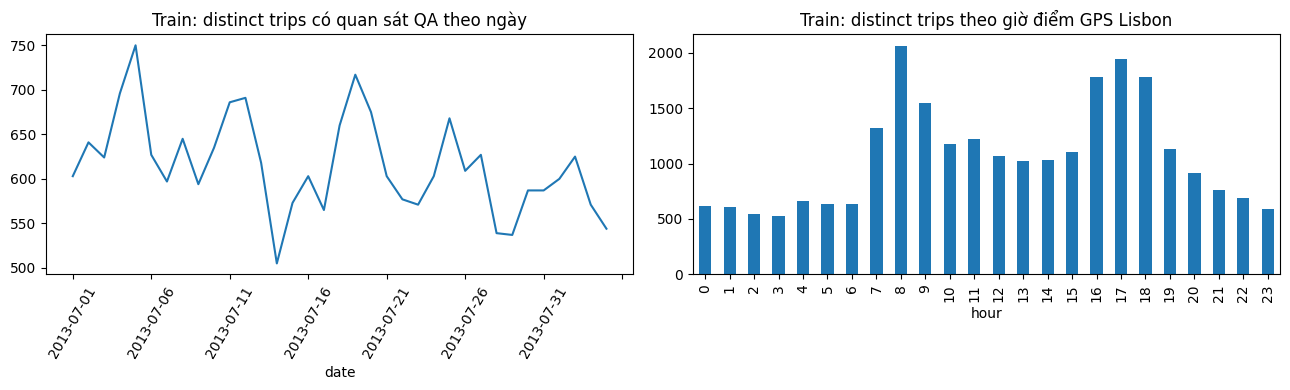

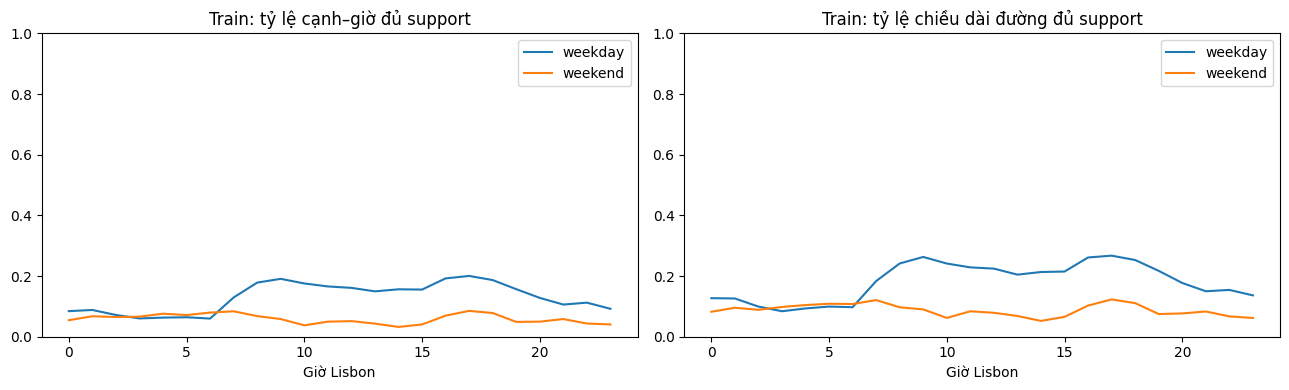

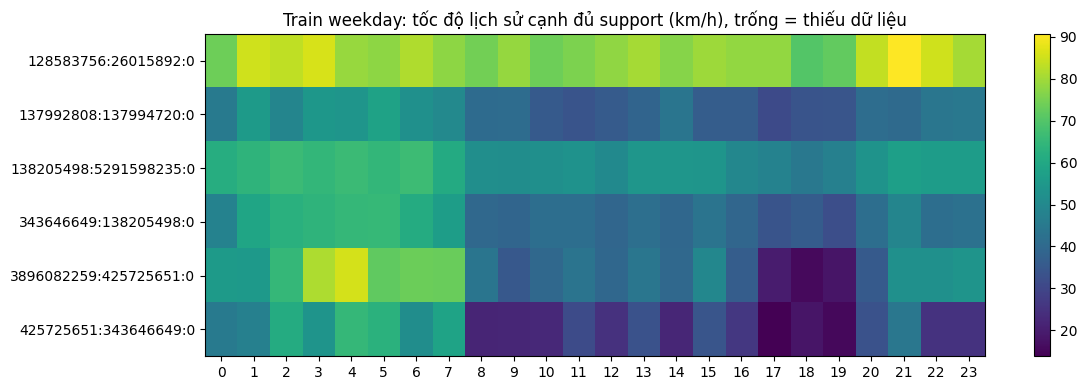

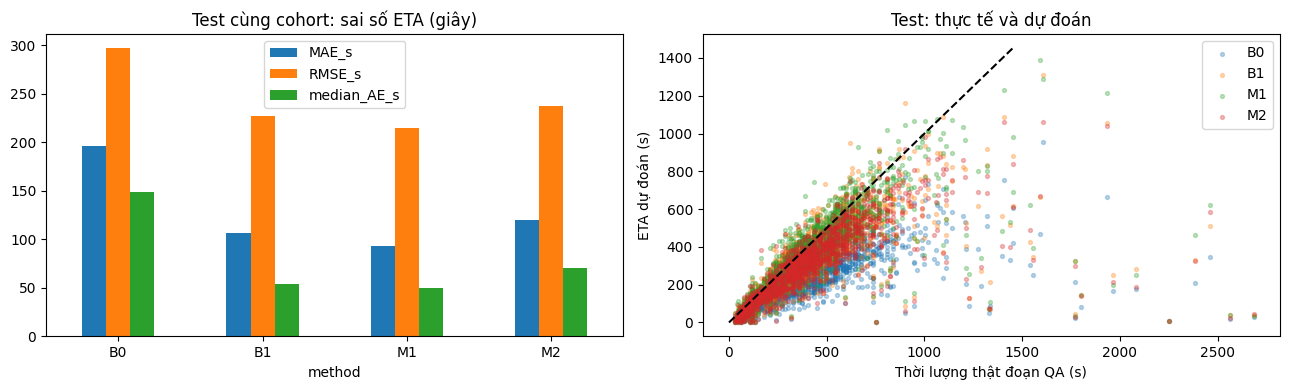

,trip_id,route_id,case_kind,actual_duration_s,predicted_duration_s,absolute_error_s,fine_support_fraction
94,1376893288620000540,1376893288620000540:1376893288620000540:seg0:c...,low_error,660.0,660.000707,0.000707,0.954719
6058,1377461775620000517,1377461775620000517:1377461775620000517:seg0:c...,low_error,45.0,44.971118,0.028882,0.000000
1310,1376994069620000017,1376994069620000017:1376994069620000017:seg0:c...,low_error,525.0,525.035021,0.035021,0.756777
266,1376907253620000100,1376907253620000100:1376907253620000100:seg1:c...,high_error,2685.0,34.205928,2650.794072,0.000000
190,1376902750620000507,1376902750620000507:1376902750620000507:seg0:c...,high_error,2565.0,41.677920,2523.322080,0.000000
4102,1377268996620000329,1377268996620000329:1377268996620000329:seg0:c...,high_error,2250.0,9.374224,2240.625776,0.000000


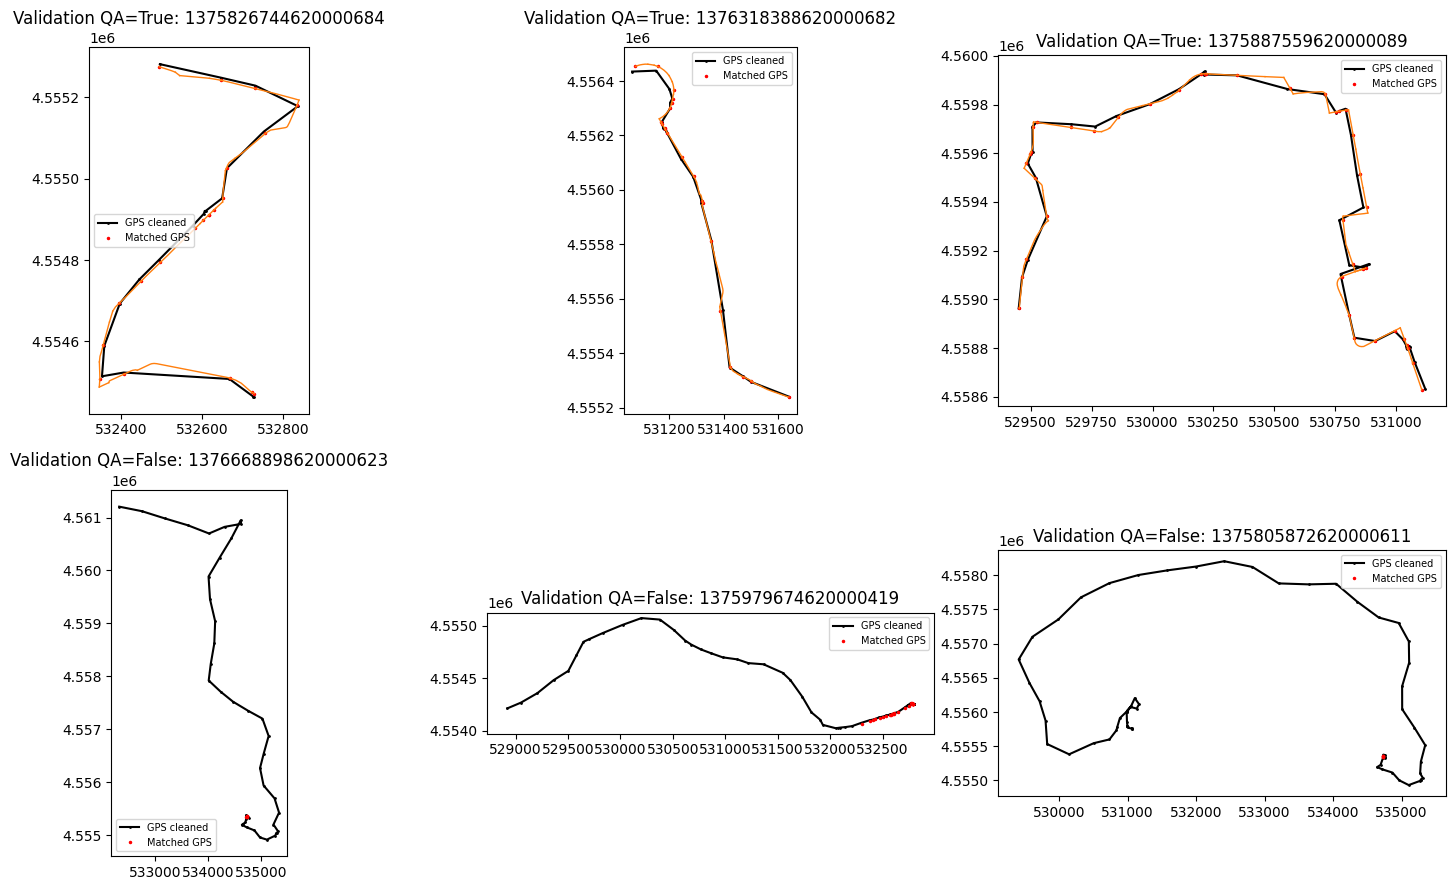

[figures] complete: Phân bố, coverage, heatmap, ETA và QA/case thành công-thất bại.
figures_and_case_studies: 3.3s; RSS cuối bước=2520 MiB


In [10]:
with timed("figures_and_case_studies"):
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    TRAIN_HOURLY.groupby("date").trip_id.nunique().plot(ax=axes[0],rot=60,title="Train: distinct trips có quan sát QA theo ngày")
    TRAIN_HOURLY.groupby("hour").trip_id.nunique().plot.bar(ax=axes[1],title="Train: distinct trips theo giờ điểm GPS Lisbon")
    save_figure("01_train_observation_distribution")
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    for label,part in COVERAGE.groupby("day_group"):
        axes[0].plot(part.slot*HISTORY["width"],part.supported_edge_fraction,label=label)
        axes[1].plot(part.slot*HISTORY["width"],part.supported_length_fraction,label=label)
    axes[0].set_title("Train: tỷ lệ cạnh–giờ đủ support");axes[1].set_title("Train: tỷ lệ chiều dài đường đủ support")
    for ax in axes: ax.set_xlabel("Giờ Lisbon");ax.set_ylim(0,1);ax.legend()
    save_figure("02_train_time_coverage")
    sufficiently=EDGE_HISTORY[EDGE_HISTORY.status.ne("insufficient_data")]
    if not sufficiently.empty:
        ids=sufficiently.groupby("edge_id").n_trips.sum().nlargest(6).index
        view=EDGE_HISTORY[EDGE_HISTORY.edge_id.isin(ids)&EDGE_HISTORY.day_group.eq("weekday")]
        matrix=view.pivot(index="edge_id",columns="slot",values="estimated_speed_kmh")
        enough=view.pivot(index="edge_id",columns="slot",values="status").ne("insufficient_data")
        matrix=matrix.where(enough)
        fig,ax=plt.subplots(figsize=(12,4));im=ax.imshow(matrix,aspect="auto",cmap="viridis")
        ax.set_yticks(range(len(matrix)),matrix.index);ax.set_xticks(range(len(matrix.columns)),matrix.columns*HISTORY["width"])
        ax.set_title("Train weekday: tốc độ lịch sử cạnh đủ support (km/h), trống = thiếu dữ liệu")
        fig.colorbar(im,ax=ax);save_figure("03_supported_edge_speed_heatmap")
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    whole=TEST_METRICS[TEST_METRICS.group=="all"].set_index("method")
    whole[["MAE_s","RMSE_s","median_AE_s"]].plot.bar(ax=axes[0],rot=0,title="Test cùng cohort: sai số ETA (giây)")
    for method,group in COMMON.groupby("method"):
        group=group.sample(min(1500,len(group)),random_state=CFG["seed"])
        axes[1].scatter(group.actual_duration_s,group.predicted_duration_s,s=8,alpha=.3,label=method)
    maximum=float(COMMON[["actual_duration_s","predicted_duration_s"]].quantile(.99).max())
    axes[1].plot([0,maximum],[0,maximum],"k--");axes[1].set(xlabel="Thời lượng thật đoạn QA (s)",ylabel="ETA dự đoán (s)",title="Test: thực tế và dự đoán")
    axes[1].legend();save_figure("04_test_eta_comparison")
    chosen=COMMON[COMMON.method.eq("M1")].copy();chosen["absolute_error_s"]=(chosen.predicted_duration_s-chosen.actual_duration_s).abs()
    CASES=pd.concat([chosen.nsmallest(3,"absolute_error_s").assign(case_kind="low_error"),chosen.nlargest(3,"absolute_error_s").assign(case_kind="high_error")])
    write_table(CASES,RUN/"test_eta_case_studies.parquet",csv=True);display(CASES[["trip_id","route_id","case_kind","actual_duration_s","predicted_duration_s","absolute_error_s","fine_support_fraction"]])
    qa=VAL_QA;example_ids=[]
    for accepted in [True,False]:
        part=qa[qa.analysis_accepted.eq(accepted)]
        if not part.empty: example_ids.extend(part.sample(min(3,len(part)),random_state=CFG["seed"]).subtrajectory_id.tolist())
    raw={}
    with (HOLDOUT_FOLDER/"validation_subtrajectories.jsonl").open(encoding="utf-8") as handle:
        for line in handle:
            item=json.loads(line)
            if item["subtrajectory_id"] in example_ids: raw[item["subtrajectory_id"]]=item
    fig,axes=plt.subplots(2,3,figsize=(15,9));lookup=EDGES.set_index("edge_id")
    points=pd.read_parquet(RUN/"validation/matching_points.parquet")
    for ax,sid in zip(axes.flat,example_ids):
        sub=raw[sid];p=pd.DataFrame(sub["points"])
        ax.plot(p.x,p.y,"k.-",markersize=2,label="GPS cleaned")
        snapped=points[points.subtrajectory_id.eq(sid)]
        if not snapped.empty: ax.plot(snapped.matched_x,snapped.matched_y,"r.",markersize=3,label="Matched GPS")
        for part in VAL_PARTS[VAL_PARTS.subtrajectory_id.eq(sid)].itertuples():
            geometry=substring(lookup.loc[part.edge_id,"geometry"],part.entry_offset_m,part.exit_offset_m)
            if isinstance(geometry,LineString): ax.plot(*geometry.xy,color="tab:orange",linewidth=1)
        accepted=bool(qa.loc[qa.subtrajectory_id.eq(sid),"analysis_accepted"].iloc[0])
        ax.set_title(f"Validation QA={accepted}: {sub['trip_id']}");ax.set_aspect("equal");ax.legend(fontsize=7)
    for ax in list(axes.flat)[len(example_ids):]:ax.axis("off")
    save_figure("05_validation_raw_matched_examples")
    record_stage("figures","complete","Phân bố, coverage, heatmap, ETA và QA/case thành công-thất bại.")

## I. Kiểm chứng kỹ thuật và kết quả bàn giao

Fixture bên dưới chỉ kiểm tra logic, không phải dữ liệu thực nghiệm Porto. Kiểm tra timestamp sau lọc,
partial distance, phân bổ thời gian, qua ranh giới giờ, không dùng thời gian thật để tích phân ETA,
chia theo toàn chuyến, missing state và mẫu số tái diễn. Kiểm tra nguồn matching train không bị sửa.

CSV nhỏ tập trung tại `outputs/csv/region_modeling/<run_key>/`; dữ liệu đầy đủ dùng Parquet để tiết kiệm.
`outputs/region_modeling/latest_run.json` chỉ cập nhật sau khi các bước hoàn tất.
Đổi hyperparameters không xóa cache GPS/matching hợp lệ; đổi dữ liệu, graph, QA hoặc code matching
tạo khóa khác. Kernel restart → Run All để tái lập; matching train luôn được tải từ nguồn đã chỉ định.

In [11]:
def technical_checks():
    checks=[]
    def check(name,condition):
        if not condition: raise AssertionError(name)
        checks.append({"test":name,"passed":True})
    start=int(pd.Timestamp("2013-08-06",tz="UTC").timestamp())
    poly=json.dumps([[-8.61,41.15],[-8.6101,41.1501],[None,41.15],[-8.6103,41.1503],[-8.6104,41.1504]])
    points,_=clean_gps(poly,start,"fixture","taxi",False)
    check("original_index_timestamp_preserved",all(p["timestamp"]==start+15*p["original_index"] for p in points))
    check("gap_not_connected",len(set(p["segment_id"] for p in points))==2)
    allocation=interval_pieces([("fixture_edge",20.,50.)],15.)
    check("partial_edge_distance",bool(allocation) and np.isclose(sum(p[3] for p in allocation),30.))
    check("original_interval_time_conserved",np.isclose(sum(p[4] for p in allocation),15.))
    t=pd.Timestamp("2013-08-06T07:59:50Z")
    fragments=list(hourly_fragments(t,t+pd.Timedelta(seconds=30),300.))
    check("hour_boundary_duration",np.isclose(sum(f["duration_s"] for f in fragments),30))
    check("hour_boundary_distance",np.isclose(sum(f["distance_traversed_m"] for f in fragments),300))
    def predictor(unit,at):
        return {"seconds_per_m":1. if at.hour==7 else 2.,"source":"fine","sufficient":True}
    eta=predict_eta([{"unit_id":"fixture","distance_m":30.}],t,None,"fixture",predictor=predictor)
    check("eta_crosses_hour_using_predicted_clock",np.isclose(eta["predicted_duration_s"],50.))
    check("full_trip_time_split",not set(TRAIN_SELECTED.trip_id)&set(HOLDOUT_SELECTED.trip_id))
    check("holdout_split_disjoint",not set(HOLDOUT_SELECTED[HOLDOUT_SELECTED.split.eq("validation")].trip_id)&set(HOLDOUT_SELECTED[HOLDOUT_SELECTED.split.eq("test")].trip_id))
    check("train_fit_scope",HISTORY["train_trip_hash"]==stable_hash(sorted(TRAIN_HOURLY.trip_id.unique())))
    check("test_not_used_to_modify_spec",file_hash(RUN/"selected_spec.json")==FROZEN_SPEC_HASH)
    check("missing_profiles_explicit",len(EDGE_HISTORY)==len(REGION_EDGES)*(7 if HISTORY["day_group"]=="weekday" else 2)*(24//HISTORY["width"]))
    observed=EDGE_HISTORY.eligible_days.fillna(0)>0
    check("recurrence_denominator_supported_days",np.allclose(EDGE_HISTORY.loc[observed,"slow_frequency"],EDGE_HISTORY.loc[observed,"slow_days"]/EDGE_HISTORY.loc[observed,"eligible_days"]))
    check("same_test_cohort_all_methods",COMMON.groupby("method").route_id.apply(set).map(lambda x:x==COMMON_IDS).all())
    check("source_artifacts_unchanged",all(file_hash(TRAIN_SOURCE/name)==h for name,h in SOURCE_HASHES.items() if name in SOURCE_FILES))
    check("partial_distance_real_holdout",np.allclose(TEST_PARTS.distance_traversed_m,TEST_PARTS.exit_offset_m-TEST_PARTS.entry_offset_m))
    check("no_test_departure_feature_leakage",not any(c in m2_features([UNIT_META.unit_id.iloc[0]],[BOUNDS[2]],UNIT_META).columns for c in ["duration_s","speed_kmh","edge_id","trip_id"]))
    return pd.DataFrame(checks)

with timed("final_verification"):
    CHECKS=technical_checks();write_table(CHECKS,RUN/"technical_checks.parquet",csv=True)
    write_json(RUN/"verification.json",{"status":"passed","n_checks":len(CHECKS),"test_routes":len(COMMON_IDS),
        "frozen_spec_hash":FROZEN_SPEC_HASH,"graph_hash":GRAPH_HASH,"source_matching_unchanged":True})
    display(CHECKS)
    record_stage("verification","complete",f"{len(CHECKS)} kiểm tra kỹ thuật đạt.")
    write_json(ROOT/CFG["output_dir"]/"latest_run.json",{"folder":str(RUN),"run_key":RUN_KEY,"stages":STAGES})
    print("Notebook hoàn tất. Metrics:",RUN/"eta_metrics.parquet")
    print("CSV:",csv_path(RUN/"eta_metrics.parquet").parent)

,test,passed
0,original_index_timestamp_preserved,True
1,gap_not_connected,True
2,partial_edge_distance,True
3,original_interval_time_conserved,True
4,hour_boundary_duration,True
5,hour_boundary_distance,True
6,eta_crosses_hour_using_predicted_clock,True
7,full_trip_time_split,True
8,holdout_split_disjoint,True
9,train_fit_scope,True


[verification] complete: 17 kiểm tra kỹ thuật đạt.
Notebook hoàn tất. Metrics: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\region_modeling\c01cada311f38e85a9d4\eta_metrics.parquet
CSV: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\csv\region_modeling\c01cada311f38e85a9d4
final_verification: 0.3s; RSS cuối bước=2521 MiB


## Tài liệu tham khảo và giới hạn diễn giải

- Yu Zheng (2015), *Trajectory Data Mining: An Overview*, PDF 41 trang có trong workspace,
  phần segmentation §3.4, map matching §3.5 và mô hình chuyển quỹ đạo sang biểu diễn đường/thời gian.
- *Trajectory_Data_Mining_Porto.pdf*, 12 trang có trong workspace: khung speed/event mining,
  coverage, taxi split consistency và offline ETA. Những hiệu chỉnh so với PDF được nêu ở đầu notebook.
- Dataset [Kaggle ECML/PKDD 2015 Porto Taxi](https://www.kaggle.com/competitions/pkdd-15-predict-taxi-service-trajectory-i/data).
- [Leuven MapMatching](https://leuvenmapmatching.readthedocs.io/en/latest/usage/introduction.html),
  [GeoPandas](https://geopandas.org/en/stable/docs/user_guide/io.html),
  [Shapely](https://shapely.readthedocs.io/en/stable/manual.html), [pyproj](https://pyproj4.github.io/pyproj/stable/).
- [pandas](https://pandas.pydata.org/docs/), [NumPy](https://numpy.org/doc/stable/),
  [PyArrow Parquet](https://arrow.apache.org/docs/python/parquet.html), [Matplotlib](https://matplotlib.org/stable/),
  [NetworkX](https://networkx.org/documentation/stable/).
- scikit-learn 1.7: [HistGradientBoostingRegressor](https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html),
  [OneHotEncoder](https://scikit-learn.org/1.7/modules/generated/sklearn.preprocessing.OneHotEncoder.html),
  [Pipeline](https://scikit-learn.org/1.7/modules/generated/sklearn.pipeline.Pipeline.html).
- [Joblib Parallel](https://joblib.readthedocs.io/en/stable/parallel.html),
  [threadpoolctl](https://github.com/joblib/threadpoolctl), [psutil](https://psutil.readthedocs.io/en/latest/).

Graph hiện tại có thể khác GPS 2013. QA chưa có ground truth độc lập; GPS 15 giây phải nội suy
thời gian trên cạnh ngắn và taxi dừng đón/trả khách có thể tạo tín hiệu chậm. Cần xem QA trực quan,
support, fallback và độ phủ test trước khi kết luận. Các số đo chỉ áp dụng cho mẫu/route đã công bố.
Không cam kết profile theo giờ hay M2 sẽ tốt hơn B1; notebook in chênh lệch thực tế và giữ kết quả thất bại.

Tài liệu bổ sung cho thành phần thực sự dùng: [Rtree](https://rtree.readthedocs.io/en/latest/), [Python sqlite3](https://docs.python.org/3/library/sqlite3.html), [nbclient](https://nbclient.readthedocs.io/en/latest/).